# 01. Phân tích khám phá dữ liệu (EDA): Hotel Booking Demand

**Mục tiêu:** hiểu dữ liệu trước khi xây mô hình, và có bằng chứng cho các quyết định ở buổi chốt M1 (danh sách cột, cách chia dữ liệu, metric).

Notebook trả lời 6 câu hỏi:

1. Dữ liệu có vấn đề chất lượng gì (thiếu, trùng, giá trị lạ)? → Mục 2
2. Target mất cân bằng đến mức nào? → Mục 3
3. Tỉ lệ hủy thay đổi theo thời gian ra sao? → Mục 4 (đầu vào cho cách chia dữ liệu, T05)
4. City Hotel và Resort Hotel khác nhau ở đâu? → Mục 5 (đầu vào cho TN2)
5. Cột nào có dấu hiệu leakage? → Mục 9 (bằng chứng cho danh sách cột ở M1)
6. Nên tạo đặc trưng mới nào? → Mục 11 (đầu vào cho T08)

**Nguyên tắc:** EDA chỉ để quan sát. Notebook này không fit scaler, encoder hay imputer nào; mọi bước xử lý cho mô hình được làm lại trong `Pipeline` và chỉ fit trên tập train.

**Lưu ý:** EDA chạy trên toàn bộ dữ liệu vì cách chia train/validation/test chưa được chốt. Vì vậy kết quả ở đây chỉ dùng để chọn cột và hướng xử lý dựa trên ý nghĩa dữ liệu, không dùng để chọn tham số mô hình. Nên ghi rõ điều này trong báo cáo.

Các ô **Nhận xét** ghi lại điều quan sát được và hệ quả cho bước xây mô hình.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from the project root or from notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from src.config import TARGET_COLUMN
from src.data import load_raw
from src.eda import MONTH_ORDER, arrival_date, cancel_rate_table, plot_cancel_rate, save_figure

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

TARGET = TARGET_COLUMN
df = load_raw()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")

119,390 rows x 32 columns


## 1. Tổng quan dữ liệu

**Mục đích:** biết mỗi cột là gì, kiểu dữ liệu gì, có bao nhiêu giá trị khác nhau. Đây là nền cho mục 2.1 của báo cáo (mô tả dataset).

In [2]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(dropna=False),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0].astype(str),
})
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
overview

Memory usage: 109.9 MB


,dtype,n_unique,n_missing,example
hotel,object,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,479,0,342
arrival_date_year,int64,3,0,2015
arrival_date_month,object,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,35,0,0
adults,int64,14,0,2


In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


### 1.1 Ý nghĩa các cột (theo bài báo gốc)

Nguồn: Antonio, de Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22, Table 1. Bài báo mô tả hai file: H1 là resort ở Algarve, H2 là khách sạn thành phố ở Lisbon (Bồ Đào Nha), mỗi file 31 biến. File CSV nhóm dùng (bản TidyTuesday/Kaggle) ghép hai file lại và thêm cột `hotel`, nên có 32 cột.

Cột "T04" là quyết định hiện tại trong `docs/feature_decisions.md`.

| Cột | Ý nghĩa | Cách tính / thời điểm (theo bài báo) | T04 |
|---|---|---|---|
| `hotel` | Resort Hotel (H1) hoặc City Hotel (H2) | Cột được thêm khi ghép hai file | KEEP |
| `is_canceled` | Booking bị hủy (1) hay không (0) | Target | TARGET |
| `lead_time` | Số ngày từ lúc booking được nhập vào hệ thống quản lý khách sạn (PMS) đến ngày đến | Ngày đến − ngày nhập | KEEP |
| `arrival_date_year`, `_month`, `_week_number`, `_day_of_month` | Năm, tháng, số tuần, ngày của ngày đến | Ngày đến có thể bị đổi (một loại thay đổi được đếm trong `booking_changes`) | KEEP |
| `stays_in_weekend_nights` | Số đêm thứ Bảy, Chủ nhật khách đã ở hoặc đặt để ở | Đếm từ tổng số đêm | REVIEW |
| `stays_in_week_nights` | Số đêm thứ Hai đến thứ Sáu khách đã ở hoặc đặt để ở | Đếm từ tổng số đêm | REVIEW |
| `adults` | Số người lớn | | REVIEW |
| `children` | Số trẻ em | Tổng trẻ em trả phí và không trả phí | REVIEW |
| `babies` | Số trẻ sơ sinh | | REVIEW |
| `meal` | Gói ăn: Undefined/SC = không có gói ăn; BB = phòng + bữa sáng; HB = bữa sáng + một bữa khác; FB = cả ba bữa | Undefined và SC cùng nghĩa | REVIEW |
| `country` | Quốc gia (mã ISO 3 ký tự) | Khách sạn thường chỉ biết đúng quốc tịch khi khách check-in | REVIEW |
| `market_segment` | Phân khúc thị trường (TA = đại lý du lịch, TO = hãng lữ hành) | | REVIEW |
| `distribution_channel` | Kênh phân phối | | REVIEW |
| `is_repeated_guest` | Khách quay lại (1) hay không (0) | 1 nếu hồ sơ khách được tạo trước ngày tạo booking | KEEP |
| `previous_cancellations` | Số booking trước đó của khách đã bị hủy | Chỉ đếm booking tạo trước booking hiện tại; 0 nếu không có hồ sơ khách | KEEP |
| `previous_bookings_not_canceled` | Số booking trước đó của khách không bị hủy | Như trên | KEEP |
| `reserved_room_type` | Mã loại phòng đã đặt | | REVIEW |
| `assigned_room_type` | Mã loại phòng được giao | Có thể khác phòng đã đặt vì lý do vận hành (vd. overbooking) hoặc theo yêu cầu khách | DROP |
| `booking_changes` | Số lần sửa booking | Đếm từ lúc nhập vào PMS **đến lúc check-in hoặc hủy** | DROP |
| `deposit_type` | No Deposit: không cọc; Non Refund: cọc bằng toàn bộ tiền phòng; Refundable: cọc dưới tổng tiền phòng | Tính từ các khoản thanh toán **trước ngày đến hoặc ngày hủy** | REVIEW |
| `agent` | Mã đại lý đặt phòng | NULL = không qua đại lý ("không áp dụng", không phải thiếu dữ liệu) | REVIEW |
| `company` | Mã công ty đặt hoặc trả tiền | NULL = không áp dụng | REVIEW |
| `days_in_waiting_list` | Số ngày booking nằm trong danh sách chờ trước khi được xác nhận | Ngày xác nhận − ngày nhập | DROP |
| `customer_type` | Contract / Group / Transient / Transient-Party | | REVIEW |
| `adr` | Giá trung bình mỗi đêm | Tổng các giao dịch tiền phòng / tổng số đêm | REVIEW |
| `required_car_parking_spaces` | Số chỗ đỗ xe khách yêu cầu | | REVIEW |
| `total_of_special_requests` | Số yêu cầu đặc biệt (vd. giường đôi, tầng cao) | | REVIEW |
| `reservation_status` | Trạng thái cuối: Canceled / Check-Out / No-Show | Trạng thái cuối cùng | DROP |
| `reservation_status_date` | Ngày đặt trạng thái cuối | Bài báo: dùng cùng `reservation_status` để biết booking bị hủy khi nào | DROP |

### 1.2 Thời điểm dữ liệu được ghi nhận

Bài báo gốc viết:

> "The data point time for each observation was defined as the day prior to each booking's arrival." (Specifications table)

> "...the variables' values were extracted from the bookings change log, with a timestamp relative to the day prior to arrival date..." (Mục 1)

> "...it is quite common for customers to change their booking's attributes, like the number of persons, staying duration, or room type preferences, either at the time of their check-in or during their stay. It is also common for hotels not to know the correct nationality of the customer until the moment of check-in." (Mục 2)

**Ý nghĩa:**
- Giá trị trong dataset là trạng thái của booking **vào ngày trước ngày đến**, không phải trạng thái lúc khách vừa đặt.
- Đề tài "dự đoán tại thời điểm đặt phòng" vì vậy chỉ làm gần đúng được.
- Cần hai việc:
  1. Xét từng cột REVIEW bằng bằng chứng ở Mục 9.
  2. Ghi giới hạn này vào phần hạn chế của báo cáo (5.3).

**Nhận xét:**

- 32 cột gồm 16 cột `int64`, 4 cột `float64` và 12 cột `object`. Xét theo ý nghĩa (không tính target):
  - 13 biến số hoặc biến đếm: `lead_time`, `stays_*`, `adults`, `children`, `babies`, `previous_*`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests`, `adr`.
  - 1 biến nhị phân: `is_repeated_guest`.
  - 4 cột mô tả ngày đến (`arrival_date_*`) và 1 cột ngày dạng chuỗi (`reservation_status_date`).
  - 12 biến phân loại: 10 cột dạng chuỗi (`hotel`, `meal`, `country`, ..., kể cả `reservation_status`) cộng với `agent` và `company`.
- Bốn cột có kiểu lưu trữ không khớp với ý nghĩa:
  - `agent`, `company` là mã ID nhưng lưu dạng `float64` (vì có NaN). Nếu để nguyên dạng số, Logistic Regression sẽ hiểu "đại lý 240 lớn hơn đại lý 9", điều này vô nghĩa. Vì vậy phải mã hóa như biến phân loại, còn NaN thành một nhóm riêng (Mục 2.1).
  - `children` là số đếm nguyên, chỉ thành `float64` vì có 4 giá trị thiếu.
  - `arrival_date_month` là tên tháng dạng chuỗi. Nếu mã hóa thứ tự theo bảng chữ cái thì "April" < "August" < "December", sai thứ tự thời gian. Cần đổi sang số 1–12 hoặc one-hot.
- **Hệ quả:** khi dựng `ColumnTransformer` (T07), nên truyền danh sách `numeric_features` và `categorical_features` tường minh theo ý nghĩa, không để tự nhận theo dtype. Nếu không, `agent` và `company` sẽ bị chuẩn hóa như biến số.

## 2. Chất lượng dữ liệu

### 2.1 Giá trị thiếu

**Mục đích:** biết cột nào thiếu, thiếu bao nhiêu, và thiếu có nghĩa gì. Theo bài báo, NULL ở `agent`/`company` nghĩa là "không áp dụng" (không qua đại lý/công ty), không phải lỗi ghi nhận. Vì vậy không nên điền bằng giá trị trung bình hay giá trị phổ biến nhất.

,n_missing,pct
children,4,0.003
country,488,0.409
agent,16340,13.686
company,112593,94.307


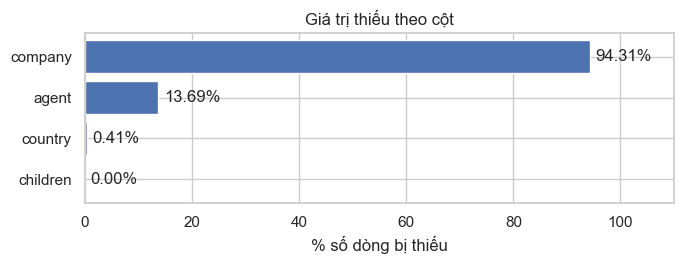

In [4]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = missing["n_missing"] / len(df) * 100
missing = missing[missing["n_missing"] > 0].sort_values("n_missing")
display(missing)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(missing.index, missing["pct"], color="#4C72B0")
for pos, pct in enumerate(missing["pct"]):
    ax.text(pct + 1, pos, f"{pct:.2f}%", va="center")
ax.set_xlim(0, 110)
ax.set_xlabel("% số dòng bị thiếu")
ax.set_title("Giá trị thiếu theo cột")
fig.tight_layout()
save_figure(fig, "missing_values")
plt.show()

In [5]:
# Is missingness itself related to cancellation?
for col in ["agent", "company", "country"]:
    flag = f"{col}_is_missing"
    display(cancel_rate_table(df.assign(**{flag: df[col].isna()}), flag))

,n_bookings,share,cancel_rate
agent_is_missing,,,
False,103050,0.863,0.390
True,16340,0.137,0.247


,n_bookings,share,cancel_rate
company_is_missing,,,
True,112593,0.943,0.382
False,6797,0.057,0.175


,n_bookings,share,cancel_rate
country_is_missing,,,
False,118902,0.996,0.371
True,488,0.004,0.137


**Nhận xét:**

- Chỉ 4 cột bị thiếu. `children` (4 dòng) và `country` (488 dòng, 0,41%) thiếu rất ít. `agent` (13,7%) và `company` (94,3%) thiếu nhiều, nhưng theo bài báo NULL ở hai cột này nghĩa là "không áp dụng", không phải lỗi ghi nhận.
- Việc thiếu có liên quan đến target: booking không qua đại lý hủy 24,7% (so với 39,0% khi có đại lý); booking có công ty hủy 17,5% (so với 38,2% khi không có).
- Nghĩa là bản thân thông tin "có hay không qua đại lý/công ty" đã là một tín hiệu dự đoán. Không nên điền bằng trung bình hay giá trị phổ biến nhất:
  - `agent`, `company` là mã ID nên "trung bình" không có nghĩa.
  - Điền giá trị phổ biến nhất (đại lý 9) sẽ gán các booking đặt trực tiếp vào một đại lý cụ thể và xóa mất tín hiệu ở trên.
- **Hệ quả (cách mã hóa):**
  - `agent`, `company`: đổi sang chuỗi, NaN thành nhóm riêng "None" (`SimpleImputer(strategy="constant")` trong Pipeline), kèm cờ `has_agent`, `has_company` (T08). Riêng `company` có 352 mức và 94,3% là NaN, nên có thể chỉ cần `has_company`.
  - `children`: điền 0 (chỉ 4 dòng).
  - `country`: nhóm "Unknown" nếu cột này được giữ (xem Mục 9).

### 2.2 Dòng trùng

**Mục đích:**
- Dataset không có mã booking. Vì vậy không biết hai dòng giống hệt nhau là một booking bị ghi hai lần, hay là nhiều booking thật của cùng một đoàn.
- Nếu chia dữ liệu ngẫu nhiên, các bản sao sẽ rơi vào cả train lẫn test. Khi đó mô hình đã "thấy" đáp án và điểm cao ảo, đây là một dạng leakage liên quan trực tiếp đến TN1.

In [6]:
status_cols = ["reservation_status", "reservation_status_date"]
n_dup = df.duplicated().sum()
n_dup_wo_status = df.drop(columns=status_cols).duplicated().sum()
print(f"Exact duplicate rows (beyond the first copy): {n_dup:,} ({n_dup / len(df):.1%})")
print(f"Duplicates when ignoring {status_cols}: {n_dup_wo_status:,}")

# Rows that have at least one identical copy
has_copy = df.duplicated(keep=False)
group_sizes = df[has_copy].groupby(list(df.columns), dropna=False).size()
print(f"Groups of identical rows: {len(group_sizes):,}; largest group: {group_sizes.max()} rows")

display(cancel_rate_table(df.assign(has_identical_copy=has_copy), "has_identical_copy"))
display(cancel_rate_table(df[has_copy], "market_segment", top=5))
display(cancel_rate_table(df[has_copy], "deposit_type"))

Exact duplicate rows (beyond the first copy): 31,994 (26.8%)
Duplicates when ignoring ['reservation_status', 'reservation_status_date']: 32,252
Groups of identical rows: 8,171; largest group: 180 rows


,n_bookings,share,cancel_rate
has_identical_copy,,,
False,79225,0.664,0.262
True,40165,0.336,0.584


,n_bookings,share,cancel_rate
market_segment,,,
Groups,16713,0.416,0.695
Offline TA/TO,12210,0.304,0.558
Online TA,8269,0.206,0.494
Corporate,1474,0.037,0.380
Direct,1405,0.035,0.238


,n_bookings,share,cancel_rate
deposit_type,,,
No Deposit,25773,0.642,0.356
Non Refund,14316,0.356,0.997
Refundable,76,0.002,0.184


**Nhận xét:**

- Có 31.994 dòng trùng hoàn toàn (26,8%), gom thành 8.171 nhóm; nhóm lớn nhất có 180 dòng giống hệt nhau.
- Dòng trùng không phân bố đều mà tập trung ở:
  - Phân khúc đoàn và đại lý: trong các dòng có bản sao, Groups chiếm 41,6%, Offline TA/TO 30,4%.
  - Đặt cọc Non Refund: 35,6% số dòng có bản sao (tỉ lệ hủy 99,7%). Nhìn từ chiều ngược lại, 98,1% dòng Non Refund có bản sao (Mục 9.3).
  - Tỉ lệ hủy của các dòng có bản sao là 58,4%, so với 26,2% ở các dòng không có bản sao.
- **Giống booking thật của đoàn hơn là lỗi ghi hai lần**, vì:
  - Một đại lý đặt nhiều phòng cho cùng một đoàn sẽ tạo ra nhiều booking cùng ngày đến, cùng loại phòng, cùng giá. Dataset không có mã booking hay tên khách nên các booking này trông giống hệt nhau.
  - Lỗi ghi hai lần thường rải đều ở mọi phân khúc, không dồn vào Groups/Non Refund như trên.
  - Khi bỏ qua hai cột trạng thái, số dòng trùng tăng từ 31.994 lên 32.252: có 258 dòng chỉ khác nhau ở trạng thái cuối hoặc ngày cập nhật trạng thái (vd. hủy vào các ngày khác nhau), tức là các booking riêng biệt.
- **Nếu chia ngẫu nhiên:** các bản sao của cùng một nhóm sẽ rơi vào cả train lẫn test. Mô hình chỉ cần "nhớ" tổ hợp giá trị của nhóm (đại lý, ngày, giá, ...) là đoán đúng nhãn ở test, nên điểm cao ảo. Ngược lại, các bản sao có cùng ngày đến và cùng `lead_time`, nên khi chia theo thời gian hoặc theo khách sạn chúng luôn nằm cùng một phía.
- **Đề xuất: giữ dòng trùng.**
  - Đây nhiều khả năng là booking thật. Bỏ đi sẽ mất 26,8% dữ liệu, làm tỉ lệ hủy giảm rõ và nhóm Non Refund gần như biến mất, tức là thay đổi chính bài toán.
  - Ảnh hưởng đến TN1: chênh lệch giữa chia ngẫu nhiên và chia theo thời gian sẽ gồm hai phần: (1) dữ liệu thay đổi theo thời gian, (2) bản sao nằm ở cả train lẫn test. Nên báo thêm tỉ lệ dòng test có bản sao trong train để giải thích phần (2). Nếu kịp, có thể chia ngẫu nhiên theo nhóm (`GroupShuffleSplit`, mỗi nhóm dòng giống hệt nhau là một group) để kiểm tra độ nhạy.

### 2.3 Giá trị bất thường hoặc không hợp lệ

**Mục đích:** tìm các giá trị vô lý về nghiệp vụ, như giá âm, booking không có khách, 0 đêm, hoặc nhãn "Undefined". Cần phân biệt **lỗi** với **trường hợp thật nhưng hiếm**.

In [7]:
guests = df[["adults", "children", "babies"]].fillna(0).sum(axis=1)
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
checks = {
    "adr < 0": df["adr"] < 0,
    "adr == 0": df["adr"] == 0,
    "adr > 1000": df["adr"] > 1000,
    "no guests (adults + children + babies == 0)": guests == 0,
    "adults == 0": df["adults"] == 0,
    "0 nights": nights == 0,
    "meal == 'Undefined'": df["meal"] == "Undefined",
    "market_segment == 'Undefined'": df["market_segment"] == "Undefined",
    "distribution_channel == 'Undefined'": df["distribution_channel"] == "Undefined",
}
anomalies = pd.DataFrame({
    "n_rows": {name: int(mask.sum()) for name, mask in checks.items()},
    "cancel_rate": {name: df.loc[mask, TARGET].mean() for name, mask in checks.items()},
})
anomalies

,n_rows,cancel_rate
adr < 0,1,0.000
adr == 0,1959,0.109
adr > 1000,1,1.000
no guests (adults + children + babies == 0),180,0.139
adults == 0,403,0.270
0 nights,715,0.049
meal == 'Undefined',1169,0.245
market_segment == 'Undefined',2,1.000
distribution_channel == 'Undefined',5,0.800


In [8]:
# Who are the zero-price bookings?
display(cancel_rate_table(df[df["adr"] == 0], "market_segment", top=5))

,n_bookings,share,cancel_rate
market_segment,,,
Complementary,680,0.347,0.135
Online TA,367,0.187,0.054
Offline TA/TO,332,0.169,0.120
Groups,252,0.129,0.095
Direct,240,0.123,0.129


In [9]:
# Checks referenced in the notes below
print("All 0-night bookings have adr == 0:", (df.loc[nights == 0, "adr"] == 0).all())
display(pd.crosstab(df["meal"], df["hotel"]))

# Rows breaking fixed business rules (candidates for removal before splitting)
invalid_rules = {
    "adr < 0": df["adr"] < 0,
    "adr > 1000": df["adr"] > 1000,
    "no guests": guests == 0,
    ">= 9 children or babies": (df["children"] >= 9) | (df["babies"] >= 9),
}
invalid = pd.concat(invalid_rules, axis=1)
print({name: int(mask.sum()) for name, mask in invalid_rules.items()})
print(f"Rows breaking at least one rule: {invalid.any(axis=1).sum()} ({invalid.any(axis=1).mean():.2%})")

All 0-night bookings have adr == 0: True


hotel,City Hotel,Resort Hotel
meal,,
BB,62305,30005
FB,44,754
HB,6417,8046
SC,10564,86
Undefined,0,1169


{'adr < 0': 1, 'adr > 1000': 1, 'no guests': 180, '>= 9 children or babies': 3}
Rows breaking at least one rule: 185 (0.15%)


**Nhận xét:**

- **Chắc chắn là lỗi:**
  - `adr` < 0 (1 dòng, −6,38): giá phòng không thể âm.
  - `adr` = 5.400 (1 dòng, booking 1 đêm cho 2 người lớn, Mục 10): giá cao kế tiếp chỉ là 510, nên gần như chắc chắn là lỗi nhập liệu.
  - Booking không có khách (180 dòng): không có ai ở thì booking không hợp lệ về nghiệp vụ.
- **Có thể là thật:**
  - `adr` = 0 (1.959 dòng): 34,7% thuộc phân khúc Complementary (phòng tặng, giá 0 là đúng); phần còn lại có thể là khuyến mãi hoặc phòng nằm trong gói. Ngoài ra, mọi booking 0 đêm đều có `adr` = 0 (xem ô code ngay trên), vì `adr` = tổng tiền phòng / số đêm. Ở các dòng này `adr` = 0 là hệ quả của cách tính chứ không phải giá thật.
  - 0 đêm (715 dòng, tỉ lệ hủy 4,9%): có thể là thuê phòng trong ngày (day-use). Tỉ lệ hủy rất thấp cho thấy phần lớn khách đã đến thật, nên giữ lại.
  - `adults` = 0 nhưng có trẻ em (403 − 180 = 223 dòng): hiếm nhưng có thể có (vd. phòng riêng cho trẻ trong một gia đình đặt nhiều phòng), nên giữ lại.
- **Nhãn `Undefined`:**
  - `meal`: theo bài báo, `Undefined` và `SC` cùng nghĩa (không có gói ăn). Thêm vào đó, `Undefined` chỉ xuất hiện ở Resort Hotel còn `SC` gần như chỉ có ở City Hotel (bảng chéo ở ô code ngay trên). Như vậy đây là hai cách ghi của hai khách sạn cho cùng một ý, và chênh lệch tỉ lệ hủy (24,5% so với 37%) chủ yếu phản ánh khác biệt giữa hai khách sạn chứ không phải khác biệt gói ăn. → **Nên gộp `Undefined` vào `SC`**. Việc này càng cần cho TN2: nếu không gộp, mô hình train trên City sẽ không bao giờ thấy mức `Undefined` của Resort.
  - `market_segment` = `Undefined` (2 dòng) và `distribution_channel` = `Undefined` (5 dòng): quá ít để học. Tỉ lệ hủy 100% hay 80% trên 2–5 dòng không có ý nghĩa thống kê. Để `OneHotEncoder` gom vào nhóm mức hiếm là đủ.
- **Hệ quả:** bỏ các dòng chắc chắn lỗi theo quy tắc nghiệp vụ cố định (`adr` < 0, `adr` > 1.000, không có khách, cùng 3 dòng có 9–10 trẻ em hoặc trẻ sơ sinh ở Mục 10), tổng cộng 185 dòng (≈ 0,15%). Vì quy tắc cố định và không học gì từ dữ liệu, có thể làm trước khi chia mà không gây leakage.

## 3. Biến mục tiêu `is_canceled`

**Mục đích:** biết tỉ lệ hai lớp để:
1. **Chọn metric.** Một mô hình luôn đoán "không hủy" đã đạt accuracy = 1 − tỉ lệ hủy, nên accuracy không nói lên nhiều. PR-AUC của một mô hình đoán ngẫu nhiên xấp xỉ tỉ lệ lớp dương, nên tỉ lệ hủy chính là mốc để so PR-AUC.
2. **Quyết định cách chia và huấn luyện:** có cần stratify, `class_weight` hay resampling không.

is_canceled
0    75166
1    44224
Cancellation rate: 37.04%; negative/positive ratio: 1.70
Accuracy of always predicting 'not canceled': 62.96%


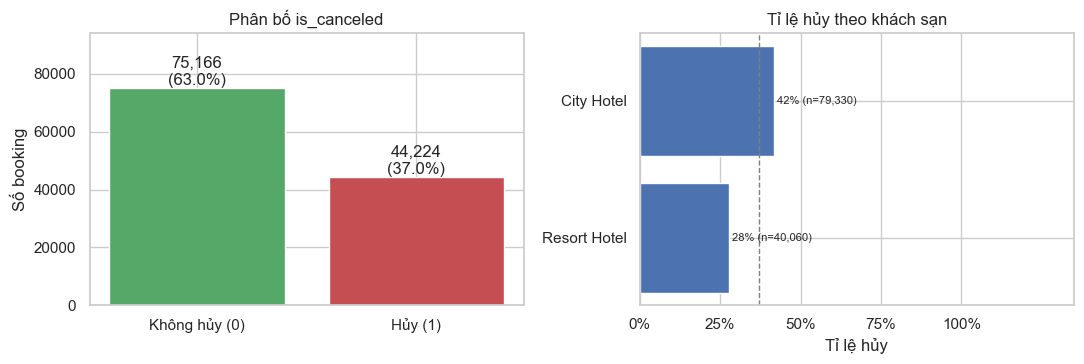

In [10]:
counts = df[TARGET].value_counts().sort_index()
pos_rate = df[TARGET].mean()
print(counts.to_string())
print(f"Cancellation rate: {pos_rate:.2%}; negative/positive ratio: {counts[0] / counts[1]:.2f}")
print(f"Accuracy of always predicting 'not canceled': {1 - pos_rate:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(["Không hủy (0)", "Hủy (1)"], counts.values, color=["#55A868", "#C44E52"])
for pos, n in enumerate(counts.values):
    axes[0].text(pos, n, f"{n:,}\n({n / len(df):.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.25)
axes[0].set_ylabel("Số booking")
axes[0].set_title("Phân bố is_canceled")
plot_cancel_rate(cancel_rate_table(df, "hotel"), axes[1], overall=pos_rate, title="Tỉ lệ hủy theo khách sạn")
fig.tight_layout()
save_figure(fig, "target_distribution")
plt.show()

**Nhận xét:**

- 44.224 booking hủy và 75.166 booking không hủy: tỉ lệ hủy 37,04%, tỉ lệ âm/dương 1,70 : 1. Đây là **mất cân bằng nhẹ**: lớp hủy chiếm hơn 1/3 dữ liệu và có hàng chục nghìn mẫu, khác hẳn các bài toán mất cân bằng nặng kiểu 1 : 100.
- **Accuracy không phù hợp làm metric chính:**
  - Mô hình luôn đoán "không hủy" đã đạt 62,96%, nên một mô hình có accuracy 70% nghe ổn nhưng thật ra chỉ hơn mốc này khoảng 7 điểm phần trăm.
  - Accuracy gộp chung hai loại lỗi (bỏ sót booking sẽ hủy và báo nhầm booking không hủy), trong khi hai loại lỗi có chi phí khác nhau (TN3).
- **PR-AUC:** mốc của mô hình ngẫu nhiên bằng tỉ lệ hủy của *tập đánh giá*, không cố định ở 0,37. Khi chia theo thời gian hoặc theo khách sạn, tỉ lệ hủy của tập test sẽ khác (City 41,7%, Resort 27,8%; theo tháng còn dao động mạnh hơn, Mục 4). Vì vậy mỗi bảng PR-AUC cần ghi kèm tỉ lệ hủy của tập test tương ứng.
- **F1 lớp hủy** phụ thuộc ngưỡng, nên ngưỡng phải chọn trên validation (TN3), không chọn trên test.
- **Hệ quả:**
  - Stratify khi chia ngẫu nhiên và khi dùng `StratifiedKFold`. Khi chia theo thời gian thì không stratify, vì thứ tự thời gian quan trọng hơn.
  - Không cần resampling (SMOTE, undersampling) ở mức 1,7 : 1. Resampling làm pipeline phức tạp hơn và dễ gây leakage nếu làm ngoài Pipeline.
  - `class_weight="balanced"` có thể thử như một siêu tham số và so trên validation. PR-AUC chỉ phụ thuộc thứ hạng điểm dự đoán nên thường thay đổi ít; tác động chính của `class_weight` là dịch xác suất, gần giống việc đổi ngưỡng.

## 4. Xu hướng theo thời gian

**Mục đích:**
- Mô hình sẽ dùng để dự đoán các booking trong tương lai. Vì vậy cần biết tỉ lệ hủy có ổn định theo thời gian không, và có mùa vụ không. Đây là đầu vào cho cách chia dữ liệu (T05, TV3).
- Có hai cách hiểu "thời gian":
  - **Ngày đến**: lấy từ các cột `arrival_date_*`.
  - **Ngày đặt**: ngày đến − `lead_time`.

Arrival dates: 2015-07-01 -> 2017-08-31
Booking dates: 2013-06-24 -> 2017-08-31


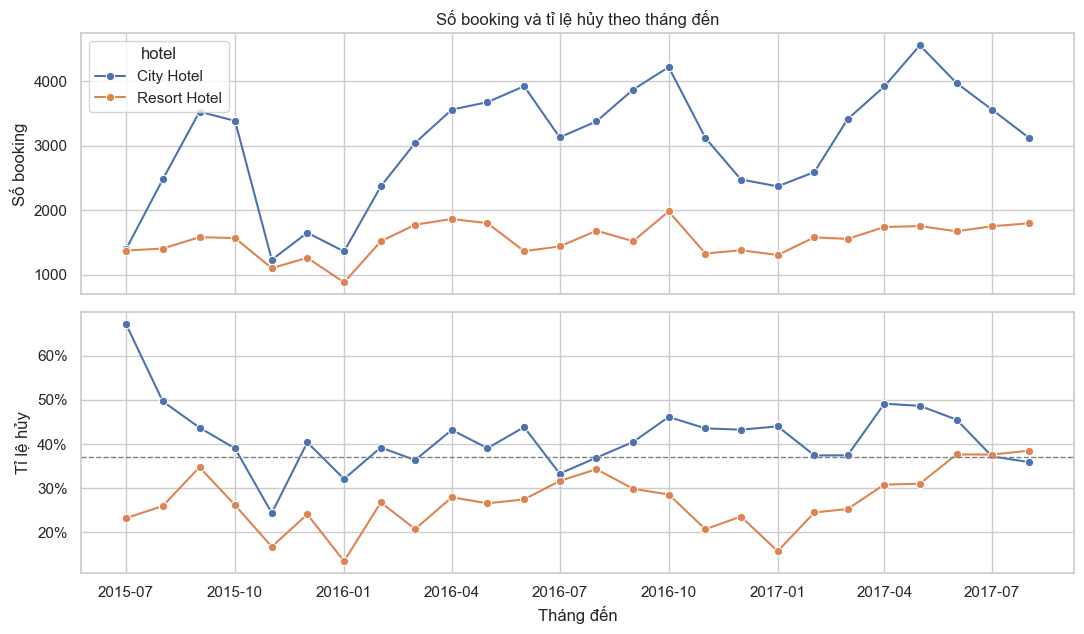

In [11]:
df_time = df.assign(arrival_date=arrival_date(df))
df_time["booking_date"] = df_time["arrival_date"] - pd.to_timedelta(df_time["lead_time"], unit="D")
print("Arrival dates:", df_time["arrival_date"].min().date(), "->", df_time["arrival_date"].max().date())
print("Booking dates:", df_time["booking_date"].min().date(), "->", df_time["booking_date"].max().date())

monthly = (
    df_time.groupby(["hotel", pd.Grouper(key="arrival_date", freq="MS")])[TARGET]
    .agg(n_bookings="size", cancel_rate="mean")
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
sns.lineplot(data=monthly, x="arrival_date", y="n_bookings", hue="hotel", marker="o", ax=axes[0])
axes[0].set_ylabel("Số booking")
axes[0].set_title("Số booking và tỉ lệ hủy theo tháng đến")
sns.lineplot(data=monthly, x="arrival_date", y="cancel_rate", hue="hotel", marker="o", ax=axes[1], legend=False)
axes[1].axhline(pos_rate, color="grey", linestyle="--", linewidth=1)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_ylabel("Tỉ lệ hủy")
axes[1].set_xlabel("Tháng đến")
fig.tight_layout()
save_figure(fig, "cancel_rate_by_month")
plt.show()

In [12]:
# Seasonality: cancellation rate by calendar month of arrival, pooled over years
by_month = (
    df.groupby(["arrival_date_month", "hotel"])[TARGET].mean()
    .unstack("hotel")
    .reindex(MONTH_ORDER)
)
by_month

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,0.397,0.148
February,0.383,0.256
March,0.369,0.229
April,0.463,0.293
May,0.444,0.288
June,0.447,0.331
July,0.409,0.314
August,0.401,0.334
September,0.420,0.324


Bảng dưới đếm booking theo **quý đặt phòng**. Dataset chỉ gồm các booking có ngày đến trong 07/2015–08/2017, nên:
- Các quý đặt phòng sớm chỉ chứa booking đặt rất xa trước ngày đến.
- Các quý cuối chỉ chứa booking đặt sát ngày đến.

Cần cân nhắc điều này nếu chia dữ liệu theo ngày đặt.

In [13]:
df_time.groupby(pd.Grouper(key="booking_date", freq="QS"))[TARGET].agg(n_bookings="size", cancel_rate="mean")

,n_bookings,cancel_rate
booking_date,,
2013-04-01,1,0.000
2013-07-01,0,NaN
2013-10-01,0,NaN
2014-01-01,1,0.000
2014-04-01,6,0.167
2014-07-01,26,0.269
2014-10-01,2603,0.911
2015-01-01,2846,0.526
2015-04-01,3295,0.395


In [14]:
# Who made the bookings in Q4/2014 (the quarter with a very high cancellation rate)?
q4_2014 = df_time[(df_time["booking_date"] >= "2014-10-01") & (df_time["booking_date"] < "2015-01-01")]
print(f"Bookings made in Q4/2014: {len(q4_2014):,}; cancellation rate {q4_2014[TARGET].mean():.1%}")
display(cancel_rate_table(q4_2014, "hotel"))
display(cancel_rate_table(q4_2014, "market_segment", top=3))
display(cancel_rate_table(q4_2014, "deposit_type"))
print("Arrival months:", q4_2014["arrival_date"].dt.to_period("M").value_counts().sort_index().to_dict())

Bookings made in Q4/2014: 2,603; cancellation rate 91.1%


,n_bookings,share,cancel_rate
hotel,,,
City Hotel,2509,0.964,0.927
Resort Hotel,94,0.036,0.489


,n_bookings,share,cancel_rate
market_segment,,,
Groups,2065,0.793,0.975
Offline TA/TO,474,0.182,0.686
Online TA,37,0.014,0.459


,n_bookings,share,cancel_rate
deposit_type,,,
Non Refund,1562,0.600,1.000
No Deposit,1041,0.400,0.777


Arrival months: {Period('2015-07', 'M'): 743, Period('2015-08', 'M'): 682, Period('2015-09', 'M'): 731, Period('2015-10', 'M'): 415, Period('2015-12', 'M'): 32}


**Nhận xét:**

- **Không so sánh trực tiếp theo năm được.** Ngày đến trải từ 01/07/2015 đến 31/08/2017: năm 2015 chỉ có tháng 7–12, năm 2017 chỉ có tháng 1–8. Mỗi năm có cơ cấu mùa khác nhau nên tỉ lệ hủy theo năm không công bằng; nếu so thì chỉ so cùng tháng giữa các năm. (Đây cũng là lý do `arrival_date_year` và `arrival_date_week_number` tương quan −0,545 ở Mục 8.)
- **Tỉ lệ hủy không ổn định theo thời gian.** Theo tháng và khách sạn, tỉ lệ hủy dao động từ 13,5% đến 67,2% (Mục 12):
  - City Hotel: rất cao ở đầu kỳ (≈ 67% với lượt đến tháng 07/2015), giảm còn ≈ 24% vào tháng 11/2015, sau đó dao động khoảng 32–49%. Đỉnh đầu kỳ trùng với nhóm booking đặt trong quý 4/2014 (2.603 booking, hủy 91,1%). Ô code ngay trên cho thấy nhóm này chủ yếu là booking đoàn của City Hotel (96% thuộc City, 79% là Groups, 60% là Non Refund), đến trong tháng 07–10/2015.
  - Resort Hotel có mùa vụ rõ hơn. Gộp các năm, tháng 1 thấp nhất (14,8%) và tháng 8 cao nhất (33,4%); mùa đông (tháng 11–1) hủy ít, mùa hè (tháng 6–9) hủy nhiều. Riêng năm 2017, tỉ lệ hủy của Resort tăng dần, lên ≈ 38% vào tháng 08/2017.
  - City ít mùa vụ hơn: gộp các năm chỉ dao động từ 36,9% (tháng 3) đến 46,3% (tháng 4).
- **Theo quý đặt phòng:** các quý từ 2013 đến quý 3/2014 gần như rỗng (riêng quý 4/2014 là khối booking đoàn nói ở trên), còn quý 3/2017 chỉ có 2.070 booking với tỉ lệ hủy 23,1%. Hai đầu bị méo do dữ liệu được cắt theo ngày đến.
- **Hệ quả:** dữ liệu thay đổi theo thời gian và có mùa vụ. Chia ngẫu nhiên giả định train và test cùng phân phối, điều không còn đúng khi mô hình dự đoán cho booking tương lai. Vì vậy chia theo thời gian nên là cách đánh giá chính, còn chia ngẫu nhiên dùng để so sánh trong TN1.

**Gợi ý cho TV3 (T05):**

1. **Lấy mốc theo ngày đến**, không theo ngày đặt:
   - Nhãn hủy/không hủy chỉ chắc chắn sau ngày đến, nên tập train chỉ nên chứa các booking đã có kết cục. Ngày đến là mốc tự nhiên.
   - Dữ liệu được cắt theo ngày đến, nên mỗi tháng đến có đủ booking ở mọi `lead_time`. Nếu chia theo ngày đặt, tập cuối chỉ còn booking đặt sát ngày (như quý 3/2017 ở trên), làm tập test lệch về `lead_time` ngắn và tỉ lệ hủy thấp.
   - Hạn chế cần ghi vào báo cáo: một số booking trong test được đặt trước khi các booking cuối của train có kết cục, nên cách chia này chỉ mô phỏng gần đúng thời điểm triển khai.
2. **Mốc cắt đề xuất** (TV3 tính lại kích thước và tỉ lệ hủy của từng tập): train 07/2015–12/2016 (18 tháng, phủ đủ một chu kỳ mùa), validation 01–04/2017, test 05–08/2017. Trade-off: validation và test rơi vào hai mùa khác nhau, nên ngưỡng chọn trên validation (TN3) có thể không tối ưu trên test; cần ghi rõ điều này.
3. **CV trên train bằng `TimeSeriesSplit`:** file CSV xếp Resort Hotel trước rồi mới đến City Hotel, và trong mỗi khách sạn cũng không xếp chặt theo ngày. Phải sort theo ngày đến trước khi dùng `TimeSeriesSplit`, nếu không các fold sẽ bị chia theo khách sạn thay vì theo thời gian.
4. **`arrival_date_year`:** khi chia theo thời gian, năm 2017 trong test không xuất hiện trong train. Logistic Regression sẽ ngoại suy xu hướng theo năm, còn mô hình cây sẽ coi 2017 như 2016. Nên cân nhắc không dùng cột này làm đặc trưng; tháng và tuần đã đủ để mô tả mùa vụ.

## 5. City Hotel và Resort Hotel

**Mục đích:** TN2 train trên một khách sạn rồi test trên khách sạn kia. Mô hình "chuyển" được hay không phụ thuộc vào hai điều:
1. Phân bố các đặc trưng ở hai khách sạn có giống nhau không.
2. Quan hệ giữa đặc trưng và việc hủy có giống nhau không.

In [15]:
hotel_summary = df.groupby("hotel").agg(
    n_bookings=(TARGET, "size"),
    cancel_rate=(TARGET, "mean"),
    median_lead_time=("lead_time", "median"),
    median_adr=("adr", "median"),
    share_non_refund=("deposit_type", lambda s: (s == "Non Refund").mean()),
    share_country_prt=("country", lambda s: (s == "PRT").mean()),
    share_online_ta=("market_segment", lambda s: (s == "Online TA").mean()),
    share_groups=("market_segment", lambda s: (s == "Groups").mean()),
    share_repeated_guest=("is_repeated_guest", "mean"),
).T
hotel_summary

hotel,City Hotel,Resort Hotel
n_bookings,79330.000,40060.000
cancel_rate,0.417,0.278
median_lead_time,74.000,57.000
median_adr,99.900,75.000
share_non_refund,0.162,0.043
share_country_prt,0.390,0.440
share_online_ta,0.488,0.443
share_groups,0.176,0.146
share_repeated_guest,0.026,0.044


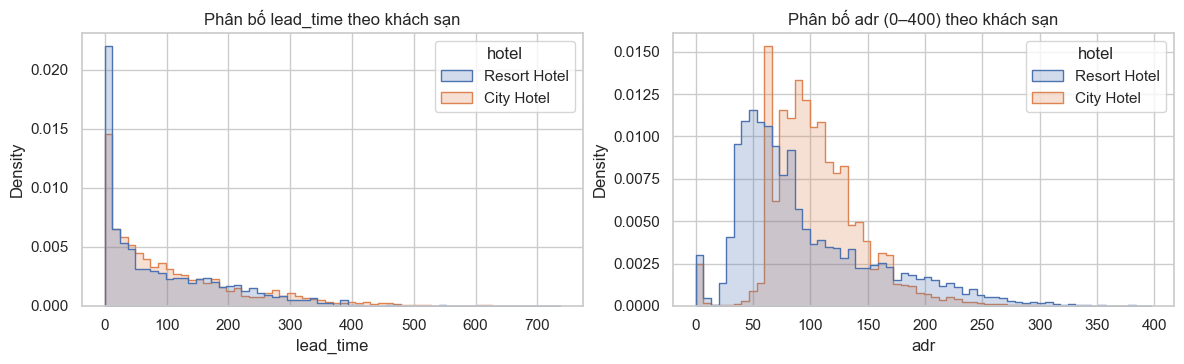

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=df, x="lead_time", hue="hotel", stat="density", common_norm=False,
             bins=60, element="step", ax=axes[0])
axes[0].set_title("Phân bố lead_time theo khách sạn")
sns.histplot(data=df[df["adr"].between(0, 400)], x="adr", hue="hotel", stat="density",
             common_norm=False, bins=60, element="step", ax=axes[1])
axes[1].set_title("Phân bố adr (0–400) theo khách sạn")
fig.tight_layout()
save_figure(fig, "city_vs_resort_distributions")
plt.show()

In [17]:
# Numbers behind the lead_time / adr / segment comparison
print("Share of bookings with lead_time <= 7 days:")
print(df.groupby("hotel")["lead_time"].apply(lambda s: (s <= 7).mean()).round(3).to_string())
display(df.groupby("hotel")["adr"].quantile([0.05, 0.5, 0.95, 0.99]).unstack())
display(pd.crosstab(df["market_segment"], df["hotel"]))

Share of bookings with lead_time <= 7 days:
hotel
City Hotel     0.136
Resort Hotel   0.223


,0.050,0.500,0.950,0.990
hotel,,,,
City Hotel,62.000,99.900,175.500,228.000
Resort Hotel,30.000,75.000,221.003,281.000


hotel,City Hotel,Resort Hotel
market_segment,,
Aviation,237,0
Complementary,542,201
Corporate,2986,2309
Direct,6093,6513
Groups,13975,5836
Offline TA/TO,16747,7472
Online TA,38748,17729
Undefined,2,0


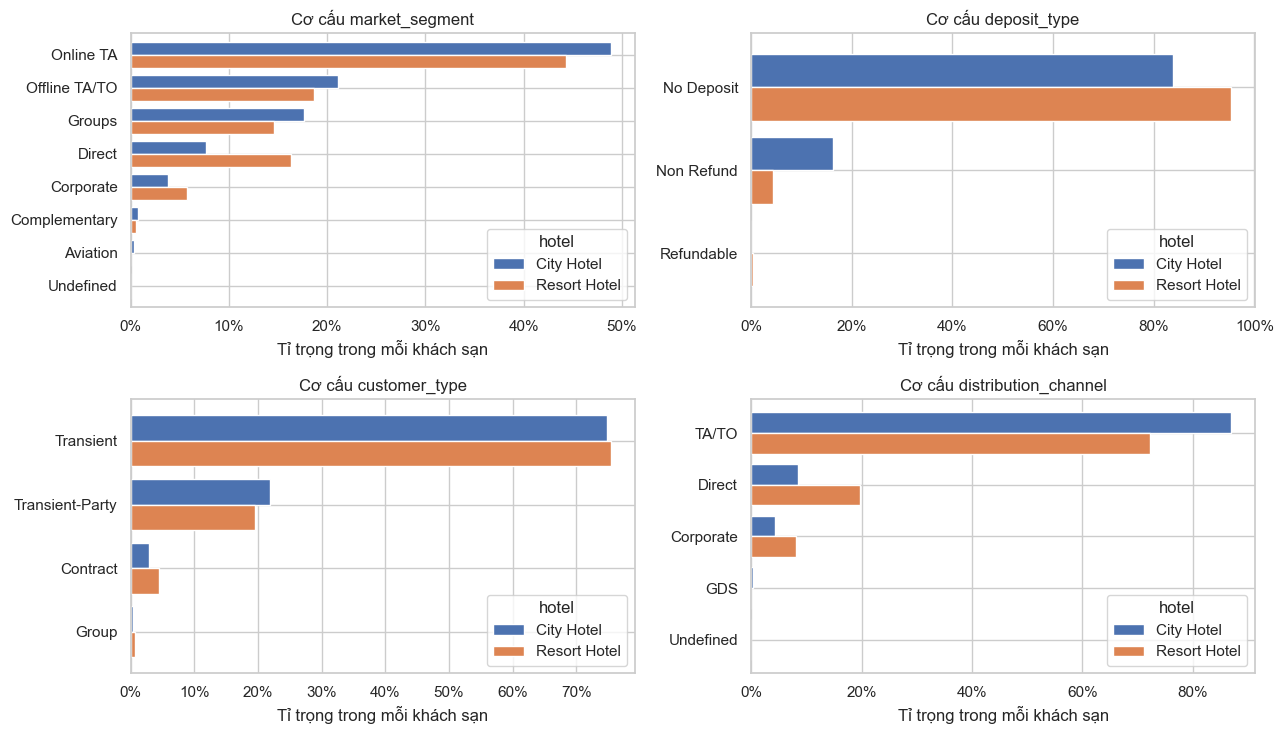

In [18]:
mix_cols = ["market_segment", "deposit_type", "customer_type", "distribution_channel"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, col in zip(axes.flat, mix_cols):
    mix = pd.crosstab(df[col], df["hotel"], normalize="columns")
    mix = mix.loc[mix.max(axis=1).sort_values(ascending=False).index]
    mix.plot.barh(ax=ax, width=0.8)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Cơ cấu {col}")
    ax.set_xlabel("Tỉ trọng trong mỗi khách sạn")
    ax.set_ylabel("")
    ax.legend(title="hotel", loc="lower right")
fig.tight_layout()
save_figure(fig, "city_vs_resort_mix")
plt.show()

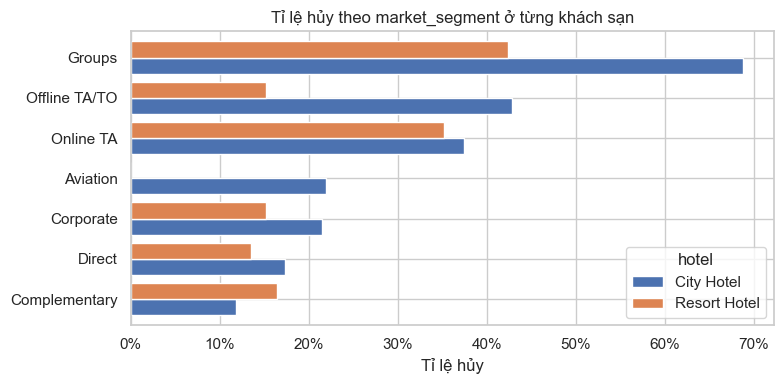

In [19]:
# Is the segment -> cancellation relationship the same in both hotels? (groups with >= 100 bookings)
seg_stats = df.groupby(["market_segment", "hotel"])[TARGET].agg(["mean", "size"])
seg_rate = seg_stats[seg_stats["size"] >= 100]["mean"].unstack("hotel")

fig, ax = plt.subplots(figsize=(8, 4))
seg_rate.sort_values("City Hotel").plot.barh(ax=ax, width=0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Tỉ lệ hủy")
ax.set_ylabel("")
ax.set_title("Tỉ lệ hủy theo market_segment ở từng khách sạn")
fig.tight_layout()
save_figure(fig, "city_vs_resort_cancel_by_segment")
plt.show()

**Nhận xét:**

- **Hai khách sạn khác nhau ở hầu hết các khía cạnh:**
  - Tỉ lệ hủy: City 41,7%, Resort 27,8%.
  - `lead_time`: trung vị 74 ngày ở City so với 57 ngày ở Resort; Resort có nhiều booking đặt sát ngày hơn (22,3% đặt trước ≤ 7 ngày, so với 13,6% ở City).
  - Giá: trung vị `adr` 99,9 ở City so với 75 ở Resort. Giá của Resort trải rộng hơn: 90% booking nằm trong khoảng 30–221, so với 62–175,5 ở City (bảng phân vị ở trên), có thể do giá theo mùa.
  - Đặt cọc: Non Refund chiếm 16,2% ở City so với 4,3% ở Resort; 88,2% booking Non Refund thuộc City (Mục 9.3).
  - Cơ cấu khách: City nghiêng về đại lý (kênh TA/TO cao hơn rõ; Online TA 48,8% so với 44,3%; Groups 17,6% so với 14,6%). Resort có tỉ trọng Direct và Corporate cao hơn, khách quay lại 4,4% so với 2,6%.
  - Cách ghi dữ liệu cũng khác: `meal` = `Undefined` chỉ có ở Resort (Mục 2.3); phân khúc Aviation hầu như chỉ có ở City.
- **Quan hệ phân khúc → hủy không giống nhau.** Cùng một phân khúc nhưng City hủy nhiều hơn rõ rệt: Groups ≈ 69% so với ≈ 42%, Offline TA/TO ≈ 43% so với ≈ 15%. Online TA gần như bằng nhau (≈ 37% và ≈ 35%), còn Direct và Corporate thấp ở cả hai. Thứ tự rủi ro giữa các phân khúc khá giống nhau (Groups và đại lý cao; Direct, Corporate, Complementary thấp), nhưng mức độ thì khác.
- Như vậy giữa hai khách sạn có cả **dịch chuyển phân bố đặc trưng** (covariate shift) lẫn **thay đổi quan hệ đặc trưng → target** (concept shift).

**Dự đoán cho TN2** (ghi lại để đối chiếu với kết quả thật):

1. Cả hai chiều đều kém hơn so với train và test trên cùng một khách sạn.
2. Khả năng xếp hạng (PR-AUC, ROC-AUC) có thể giữ được một phần vì thứ tự rủi ro giữa các phân khúc tương tự. Xác suất dự đoán thì sẽ lệch:
   - City → Resort: dự đoán hủy quá cao, nên precision giảm (nhiều báo nhầm).
   - Resort → City: dự đoán hủy quá thấp, nên recall giảm (bỏ sót nhiều).
   - Ngưỡng chọn ở khách sạn này sẽ không tối ưu ở khách sạn kia.
3. **City → Resort có thể tốt hơn chiều ngược lại:** City có gần gấp đôi dữ liệu và đa dạng hơn (nhiều Non Refund, nhiều đoàn), còn mô hình train trên Resort thấy rất ít ví dụ về các nhóm hủy nhiều nhất của City (Non Refund chỉ 4,3%; Offline TA/TO ở Resort hủy ít). Đây mới là giả thuyết.
4. **Cách so:** không so PR-AUC thô giữa hai chiều, vì mốc khác nhau (0,278 khi test trên Resort, 0,417 khi test trên City). Nên so mức PR-AUC vượt mốc, hoặc so thêm ROC-AUC (không phụ thuộc tỉ lệ lớp).
5. **Lưu ý khi cài đặt:** cột `hotel` là hằng số trong TN2 nên phải bỏ; gộp `meal` `Undefined` → `SC` trước khi chia.

## 6. Biến số và target

**Mục đích:**
- Xem biến số nào phân biệt rõ booking hủy với booking không hủy.
- Xem phân phối có lệch mạnh không. Logistic Regression nhạy với biến lệch và khác thang đo, nên có thể cần log hoặc chuẩn hóa trong Pipeline. Mô hình cây gần như không bị ảnh hưởng.

In [20]:
numeric_cols = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "adr", "previous_cancellations", "previous_bookings_not_canceled", "total_of_special_requests",
    "required_car_parking_spaces", "booking_changes", "days_in_waiting_list",
]
by_class = df.groupby(TARGET)[numeric_cols].agg(["mean", "median"]).T.unstack()
by_class.columns = [f"{stat}_{'canceled' if cls else 'not_canceled'}" for cls, stat in by_class.columns]
by_class["skew"] = df[numeric_cols].skew()
by_class

,mean_not_canceled,median_not_canceled,mean_canceled,median_canceled,skew
lead_time,79.985,45.000,144.849,113.000,1.347
stays_in_weekend_nights,0.929,1.000,0.925,1.000,1.380
stays_in_week_nights,2.464,2.000,2.562,2.000,2.862
adults,1.830,2.000,1.902,2.000,18.318
children,0.102,0.000,0.107,0.000,4.113
babies,0.010,0.000,0.004,0.000,24.647
adr,99.988,92.500,104.964,96.200,10.530
previous_cancellations,0.016,0.000,0.208,0.000,24.458
previous_bookings_not_canceled,0.203,0.000,0.025,0.000,23.540
total_of_special_requests,0.714,1.000,0.329,0.000,1.349


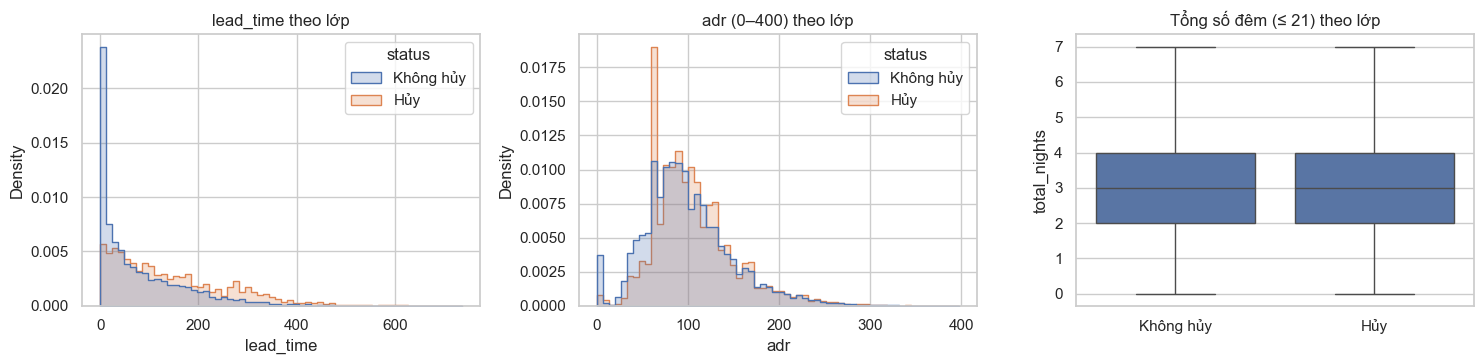

In [21]:
plot_df = df.assign(
    total_nights=df["stays_in_weekend_nights"] + df["stays_in_week_nights"],  # viewing only
    status=df[TARGET].map({0: "Không hủy", 1: "Hủy"}),
)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(data=plot_df, x="lead_time", hue="status", stat="density", common_norm=False,
             bins=60, element="step", ax=axes[0])
axes[0].set_title("lead_time theo lớp")
sns.histplot(data=plot_df[plot_df["adr"].between(0, 400)], x="adr", hue="status", stat="density",
             common_norm=False, bins=60, element="step", ax=axes[1])
axes[1].set_title("adr (0–400) theo lớp")
sns.boxplot(data=plot_df[plot_df["total_nights"] <= 21], x="status", y="total_nights",
            showfliers=False, ax=axes[2])
axes[2].set_title("Tổng số đêm (≤ 21) theo lớp")
axes[2].set_xlabel("")
fig.tight_layout()
save_figure(fig, "numeric_by_target")
plt.show()

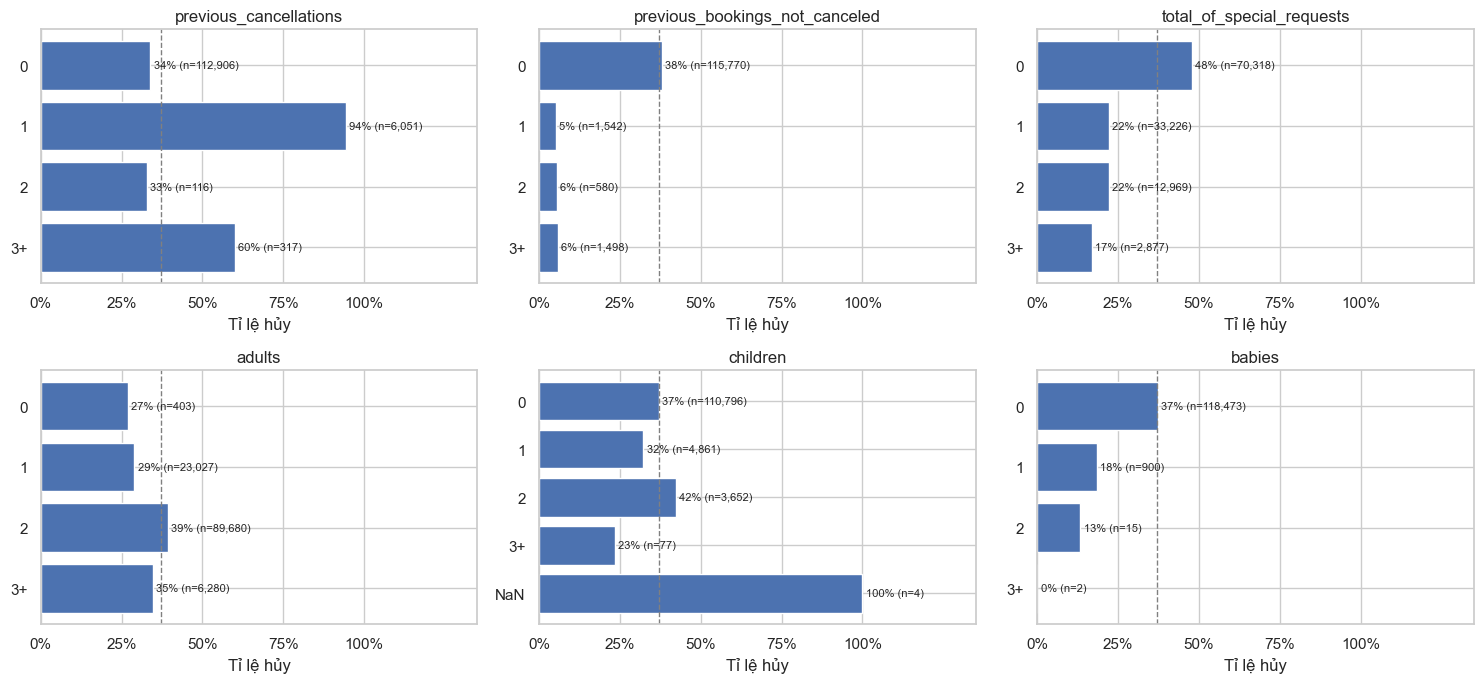

In [22]:
# Cancellation rate by small count values; the long tail is grouped into "3+"
count_cols = ["previous_cancellations", "previous_bookings_not_canceled", "total_of_special_requests",
              "adults", "children", "babies"]


def bucket(value):
    if pd.isna(value):
        return "NaN"
    return "3+" if value >= 3 else str(int(value))


fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, count_cols):
    table = cancel_rate_table(df.assign(value=df[col].map(bucket)), "value").sort_index()
    plot_cancel_rate(table, ax, overall=pos_rate, title=col)
    ax.set_ylabel("")
fig.tight_layout()
save_figure(fig, "cancel_rate_by_count")
plt.show()

In [23]:
# Cancellation rate of last-minute bookings
for days in [7, 30]:
    rate = df.loc[df["lead_time"] <= days, TARGET].mean()
    print(f"lead_time <= {days} days: cancellation rate {rate:.1%}")

# Who are the bookings with exactly one previous cancellation?
prev1 = df["previous_cancellations"] == 1
print(f"previous_cancellations == 1: {prev1.sum():,} rows, cancellation rate {df.loc[prev1, TARGET].mean():.1%}")
print(f"  share Non Refund: {(df.loc[prev1, 'deposit_type'] == 'Non Refund').mean():.1%}")
print(f"  share Groups: {(df.loc[prev1, 'market_segment'] == 'Groups').mean():.1%}")
print(f"  share with an identical copy: {df.duplicated(keep=False)[prev1].mean():.1%}")

lead_time <= 7 days: cancellation rate 9.6%
lead_time <= 30 days: cancellation rate 18.6%
previous_cancellations == 1: 6,051 rows, cancellation rate 94.4%
  share Non Refund: 58.4%
  share Groups: 53.5%
  share with an identical copy: 83.2%


**Nhận xét:**

- **`lead_time` phân biệt rõ nhất:** booking hủy có trung vị 113 ngày, booking không hủy chỉ 45 ngày (trung bình 145 so với 80). Booking đặt sát ngày ít hủy (`lead_time` ≤ 7 ngày: 9,6%; ≤ 30 ngày: 18,6%, so với 37,0% chung), còn lớp hủy dày hơn ở vùng 200–400 ngày. Spearman với target là 0,317, cao nhất trong các biến số (Mục 8). Biến này biết được ngay lúc đặt, nên là đặc trưng hợp lệ quan trọng nhất.
- **Các biến khác có chênh lệch rõ:**
  - `total_of_special_requests`: không có yêu cầu thì hủy 48%; có 1–2 yêu cầu chỉ 22%; từ 3 yêu cầu trở lên 17%.
  - `required_car_parking_spaces`: trung bình ở lớp hủy đúng bằng 0, nghĩa là **không booking nào có yêu cầu đỗ xe bị hủy**. Kết quả quá hoàn hảo, nghi leakage (Mục 9).
  - Lịch sử khách: `previous_bookings_not_canceled` ≥ 1 chỉ hủy 5–6%. `previous_cancellations` = 1 hủy tới 94% (n = 6.051) nhưng = 2 chỉ 33%, một mức bất thường. Ô code ở trên cho thấy trong các dòng `previous_cancellations` = 1, 83,2% có dòng trùng, 58,4% là Non Refund và 53,5% thuộc Groups, nên tín hiệu này có thể đến từ các khối booking đoàn hơn là thói quen của khách cá nhân. Cần để ý khi đọc feature importance.
  - `booking_changes` (trung bình 0,10 so với 0,29) và `days_in_waiting_list` (3,56 so với 1,59) cũng khác nhau, nhưng đều là cột DROP. Chẳng hạn `booking_changes` được đếm đến lúc check-in hoặc hủy, nên booking hủy sớm có ít thời gian để bị sửa.
- **Các biến yếu:** `adr` (trung vị 96,2 so với 92,5; ρ = 0,05), tổng số đêm (trung vị 3, IQR 2–4 ở cả hai lớp), `adults`/`children` (tỉ lệ hủy theo từng mức nằm trong khoảng 23–42%). Đỉnh nhọn quanh `adr` ≈ 60 ở lớp hủy nhiều khả năng do các khối booking đoàn cùng giá. Các biến này vẫn có thể có ích khi kết hợp với biến khác trong mô hình cây.
- **Độ lệch:** `lead_time` lệch vừa (1,35); `adr` (10,5), `days_in_waiting_list` (11,9), `adults` (18,3), `babies` (24,6) và `previous_*` (≈ 24) lệch rất mạnh vì phần lớn giá trị bằng 0 và có đuôi dài.
  - Logistic Regression là mô hình tuyến tính trên log-odds: vài giá trị cực lớn sẽ kéo hệ số, và `StandardScaler` chỉ đổi thang đo chứ không giảm độ lệch. Cần `log1p` cho `lead_time` và `adr` (cắt `adr` ≥ 0 trước); các biến đếm thưa (`previous_*`, `babies`) đổi thành cờ 0/≥ 1 hoặc nhóm 0/1/2+, sau đó mới chuẩn hóa. Tất cả đặt trong Pipeline.
  - Mô hình cây (RF, GBM) chỉ dùng thứ tự giá trị để chia nhánh, nên không bị ảnh hưởng bởi độ lệch hay thang đo và không cần biến đổi.
- **`total_of_special_requests` có thể được ghi nhận sau lúc đặt:** giá trị là trạng thái ngày trước ngày đến, nên các yêu cầu khách gửi thêm sau khi đặt cũng được cộng vào. Tuy vậy, tỉ lệ hủy giảm mạnh nhưng không về 0% (vẫn 17–22%), khác hẳn trường hợp đỗ xe, và nhiều yêu cầu được nhập ngay trên form đặt phòng. Quyết định ở Mục 9.3.

## 7. Biến phân loại và target

**Mục đích:**
- Xem tỉ lệ hủy theo từng nhóm.
- Đếm số mức (cardinality) của mỗi biến để chọn cách mã hóa:
  - Biến ít mức: one-hot.
  - Biến nhiều mức như `country`, `agent`, `company`: cần gom các mức hiếm.

In [24]:
categorical_cols = ["hotel", "meal", "country", "market_segment", "distribution_channel",
                    "reserved_room_type", "deposit_type", "customer_type", "agent", "company"]
rows = {}
for col in categorical_cols:
    shares = df[col].value_counts(normalize=True, dropna=False)
    rows[col] = {
        "n_levels": df[col].nunique(),
        "top_level": str(shares.index[0]),
        "top_share": shares.iloc[0],
        "n_levels_below_1pct": int((shares < 0.01).sum()),
    }
pd.DataFrame(rows).T.astype({"n_levels": int, "top_share": float, "n_levels_below_1pct": int})

,n_levels,top_level,top_share,n_levels_below_1pct
hotel,2,City Hotel,0.664,0
meal,5,BB,0.773,2
country,177,PRT,0.407,164
market_segment,8,Online TA,0.473,3
distribution_channel,5,TA/TO,0.820,2
reserved_room_type,10,A,0.720,5
deposit_type,3,No Deposit,0.876,1
customer_type,4,Transient,0.751,1
agent,333,9.0,0.268,321
company,352,nan,0.943,352


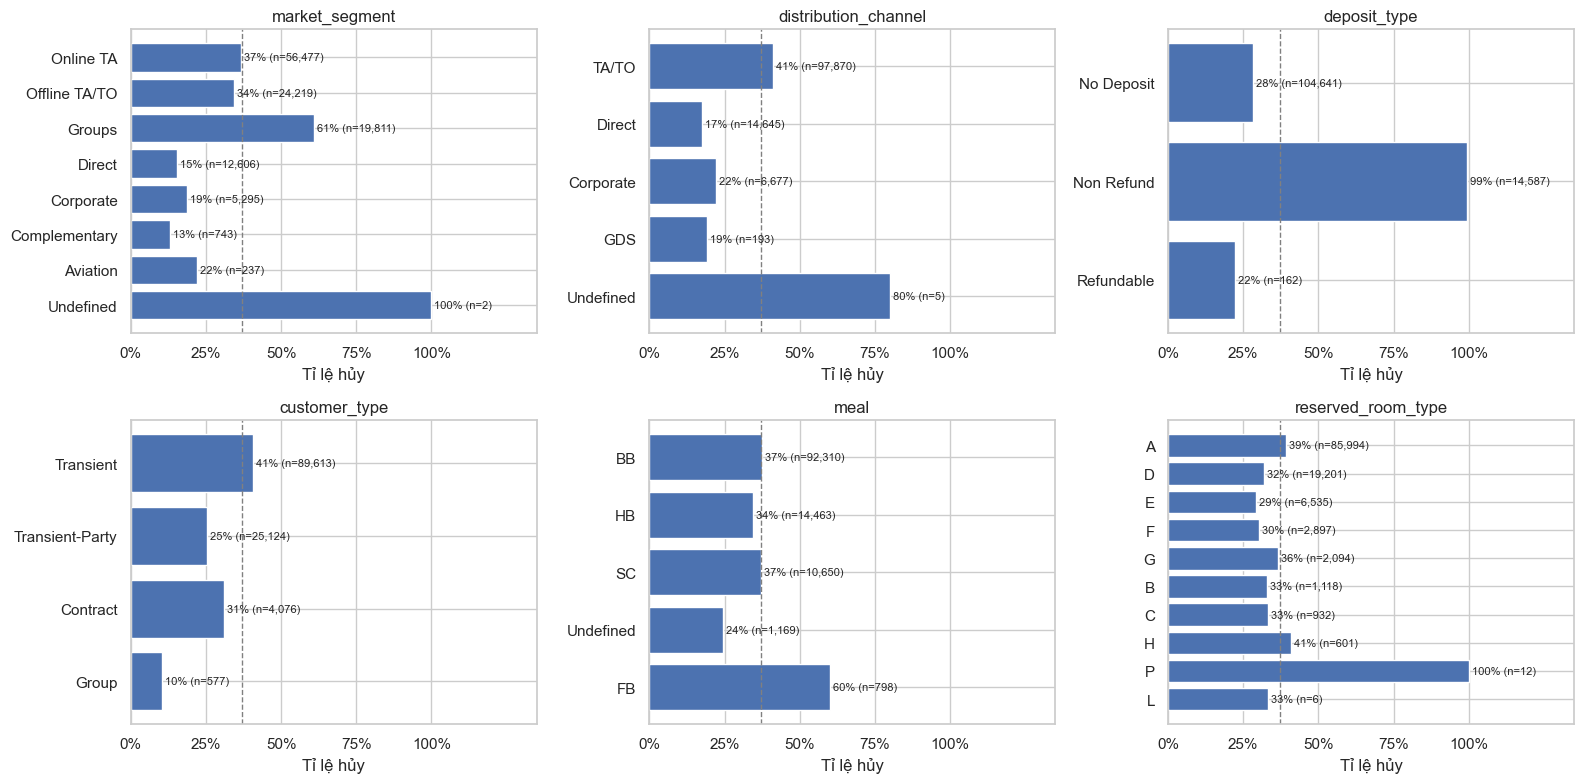

In [25]:
cat_plot_cols = ["market_segment", "distribution_channel", "deposit_type",
                 "customer_type", "meal", "reserved_room_type"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cat_plot_cols):
    plot_cancel_rate(cancel_rate_table(df, col), ax, overall=pos_rate, title=col)
fig.tight_layout()
save_figure(fig, "cancel_rate_by_category")
plt.show()

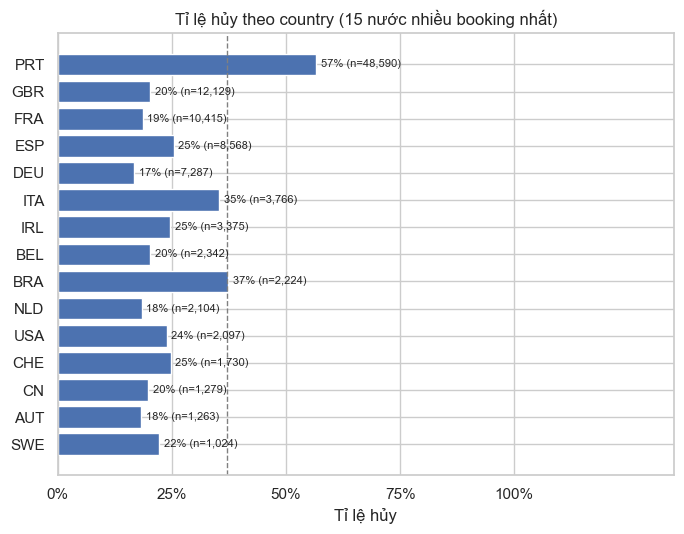

In [26]:
fig, ax = plt.subplots(figsize=(7, 5.5))
plot_cancel_rate(cancel_rate_table(df, "country", top=15), ax, overall=pos_rate,
                 title="Tỉ lệ hủy theo country (15 nước nhiều booking nhất)")
fig.tight_layout()
save_figure(fig, "cancel_rate_by_country")
plt.show()

**Nhận xét:**

- **Nhóm hủy cao bất thường:**
  - `deposit_type` = Non Refund: 99% (n = 14.587), ngược trực giác vì khách đã trả trước toàn bộ tiền phòng lại hủy nhiều nhất. Xem kỹ ở Mục 9.3.
  - `country` = PRT: 57% (n = 48.590), cao gấp 1,5–3 lần các nước khác trong top 15 (17–37%). Đáng ngờ vì bài báo nói quốc tịch thường chỉ đúng khi check-in (Mục 9).
  - `market_segment` = Groups 61%, `meal` = FB 60% (n = 798), `customer_type` = Transient 41%, `distribution_channel` = TA/TO 41%.
- **Nhóm hủy thấp:** Direct 15%, Complementary 13%, Corporate 19%; `customer_type` = Group 10%; Refundable 22%. Phần lớn là các nhóm có quan hệ trực tiếp với khách sạn hoặc đặt theo thỏa thuận, nên hợp lý về nghiệp vụ.
- **Gần 0% hoặc 100% nhưng rất ít mẫu:** `market_segment` = Undefined 100% (n = 2), `distribution_channel` = Undefined 80% (n = 5), `reserved_room_type` = P 100% (n = 12). Đây là nhiễu do cỡ mẫu nhỏ chứ không phải leakage, nên gom vào nhóm hiếm để mô hình không học thuộc chúng.
- `reserved_room_type`: các loại phòng phổ biến có tỉ lệ hủy 29–41%, chênh lệch nhỏ.
- **Số mức:** hầu hết biến có ≤ 10 mức, dùng one-hot trực tiếp được. Ba biến nhiều mức: `country` 177 mức (164 mức < 1%), `agent` 333 mức (321 mức < 1%), `company` 352 mức (mọi mức đều < 1%, 94,3% là NaN).
- **Hệ quả (cách mã hóa):**
  - Dùng `OneHotEncoder(min_frequency=..., handle_unknown="infrequent_if_exist")` (scikit-learn 1.5 có hỗ trợ), fit trong Pipeline trên train. Các mức hiếm và các mức mới chỉ có ở test sẽ rơi vào chung nhóm "infrequent". Ngưỡng tần suất được tính trên train, không lấy số đếm ở notebook này (vốn tính trên toàn bộ dữ liệu).
  - `company`: chỉ dùng cờ `has_company`. `agent`: các đại lý phổ biến + "Other" + "None". `country` (nếu được giữ): PRT / nước khác / thiếu, hoặc top-N.
  - Không dùng target encoding tính trên toàn bộ dữ liệu, vì làm vậy là rò target. Nếu cần thì dùng `TargetEncoder` (có cross-fitting) trong Pipeline; tuy vậy one-hot đơn giản và dễ giải thích hơn trong báo cáo.

## 8. Tương quan giữa các biến số

**Mục đích:**
- Tìm các cặp biến gần như mang cùng thông tin (đa cộng tuyến, multicollinearity). Hiện tượng này làm hệ số của Logistic Regression khó diễn giải, nhưng ít ảnh hưởng đến mô hình cây.
- Dùng tương quan **Spearman** (dựa trên thứ hạng) vì nhiều biến lệch mạnh hoặc là biến đếm.

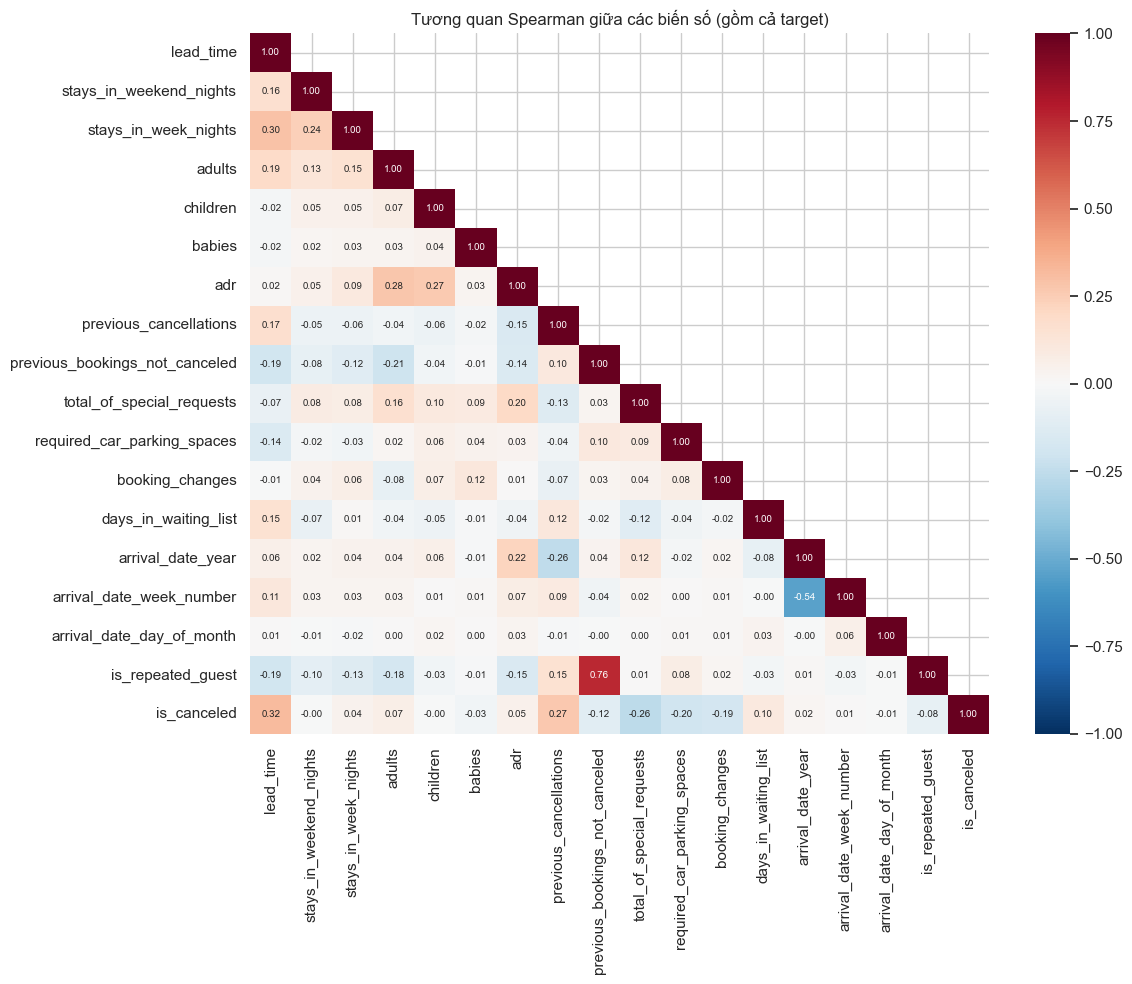

In [27]:
corr_cols = numeric_cols + ["arrival_date_year", "arrival_date_week_number",
                            "arrival_date_day_of_month", "is_repeated_guest", TARGET]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Tương quan Spearman giữa các biến số (gồm cả target)")
fig.tight_layout()
save_figure(fig, "correlation_heatmap")
plt.show()

In [28]:
feat_corr = corr.drop(index=TARGET, columns=TARGET)
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1)).stack()
top_pairs = upper.reindex(upper.abs().sort_values(ascending=False).index).head(8)
display(top_pairs.rename("spearman").to_frame())
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
        .rename("spearman_with_target").to_frame())

,,spearman
previous_bookings_not_canceled,is_repeated_guest,0.757
arrival_date_year,arrival_date_week_number,-0.545
lead_time,stays_in_week_nights,0.296
adults,adr,0.280
children,adr,0.265
previous_cancellations,arrival_date_year,-0.258
stays_in_weekend_nights,stays_in_week_nights,0.238
adr,arrival_date_year,0.220


,spearman_with_target
lead_time,0.317
previous_cancellations,0.270
total_of_special_requests,-0.259
required_car_parking_spaces,-0.197
booking_changes,-0.185
previous_bookings_not_canceled,-0.115
days_in_waiting_list,0.098
is_repeated_guest,-0.085
adults,0.067
adr,0.051


**Nhận xét:**

- **Chỉ có 2 cặp với |ρ| > 0,5:**
  - `previous_bookings_not_canceled` – `is_repeated_guest` (0,757): hợp lý, vì khách quay lại thường đã có booking trước đó. Hai cột chồng lấn nhưng không trùng hoàn toàn. Mô hình cây giữ cả hai không sao. Với Logistic Regression, hệ số của hai cột sẽ khó diễn giải riêng; regularization L2 (mặc định) giảm bớt vấn đề này, hoặc gộp lịch sử thành `prev_cancel_ratio` + `has_history` (T08).
  - `arrival_date_year` – `arrival_date_week_number` (−0,545): không phải quan hệ thật mà do khoảng thời gian của dữ liệu. Năm 2015 chỉ có các tuần nửa cuối năm, năm 2017 chỉ có các tuần nửa đầu năm, nên năm thấp đi kèm tuần cao. Điều này cho thấy `arrival_date_year` giống một "chỉ số thời gian" hơn là đặc trưng (xem gợi ý ở Mục 4).
- Các cặp còn lại đều có |ρ| ≤ 0,30, nên **không có đa cộng tuyến nghiêm trọng** giữa các biến số. Lưu ý `arrival_date_month` là chuỗi nên không có trong heatmap; tháng và tuần gần như mang cùng thông tin mùa vụ, nên với Logistic Regression chỉ cần một trong hai.
- **Tương quan với target:**
  - Mạnh nhất là `lead_time` (0,317), biến có sẵn lúc đặt.
  - Tiếp theo là `previous_cancellations` (0,270, xem lưu ý ở Mục 6), `total_of_special_requests` (−0,259), `required_car_parking_spaces` (−0,197) và `booking_changes` (−0,185). Trong đó `required_car_parking_spaces` và `booking_changes` bị loại khỏi bộ sạch (Mục 9.3); `total_of_special_requests` được giữ nhưng vẫn có rủi ro được ghi nhận sau lúc đặt (Mục 6). Cùng với `deposit_type` và `country` bị loại, bộ cột sạch sẽ mất khá nhiều tín hiệu. Dự kiến TN1 sẽ cho thấy khoảng cách rõ giữa hai bộ cột.
  - Mọi |ρ| với target đều ≤ 0,32: không biến số đơn lẻ nào quyết định target. Tín hiệu mạnh nhất nằm ở biến phân loại (`deposit_type`, `country`, `market_segment`, Mục 7). Spearman chỉ đo quan hệ đơn điệu theo từng cặp, không bắt được tương tác giữa các biến.

## 9. Bằng chứng leakage (đầu vào cho M1)

Phần này kết hợp hai nguồn:
1. **Ý nghĩa và thời điểm ghi nhận** của cột theo bài báo (Mục 1.1, 1.2).
2. **Dấu hiệu thống kê:** nếu một điều kiện làm tỉ lệ hủy gần 0% hoặc gần 100% trên nhiều booking, điều kiện đó đáng ngờ.

Thống kê chỉ là dấu hiệu. Quyết định cuối cùng dựa trên câu hỏi: *"Lúc khách vừa đặt phòng, khách sạn đã biết giá trị này chưa?"* Đối chiếu với `docs/feature_decisions.md` (T04).

### 9.1 `reservation_status`

In [29]:
pd.crosstab(df["reservation_status"], df[TARGET], margins=True)

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


### 9.2 `reservation_status_date` so với ngày đến

Với booking bị hủy, ngày này là ngày hủy. Biết ngày này tức là biết booking đã bị hủy và hủy khi nào.

In [30]:
gap_days = (pd.to_datetime(df["reservation_status_date"]) - df_time["arrival_date"]).dt.days
display(gap_days.groupby(df["reservation_status"]).describe().round(1))
share_before = (gap_days[df[TARGET] == 1] < 0).mean()
print(f"Canceled bookings whose status date is before the arrival date: {share_before:.1%}")

,count,mean,std,min,25%,50%,75%,max
reservation_status,,,,,,,,
Canceled,43017.000,-88.300,90.800,-526.000,-130.000,-56.000,-19.000,0.000
Check-Out,75166.000,3.400,2.600,0.000,2.000,3.000,4.000,69.000
No-Show,1207.000,-0.100,3.200,-111.000,0.000,0.000,0.000,0.000


Canceled bookings whose status date is before the arrival date: 95.3%


### 9.3 Các điều kiện đáng ngờ

,n_bookings,cancel_rate_if_true,cancel_rate_if_false
assigned_room_type != reserved_room_type,14917,0.054,0.416
booking_changes > 0,18076,0.157,0.409
days_in_waiting_list > 0,3698,0.638,0.362
required_car_parking_spaces > 0,7416,0.000,0.395
total_of_special_requests > 0,49072,0.217,0.477
deposit_type == 'Non Refund',14587,0.994,0.284
country == 'PRT',48590,0.566,0.236


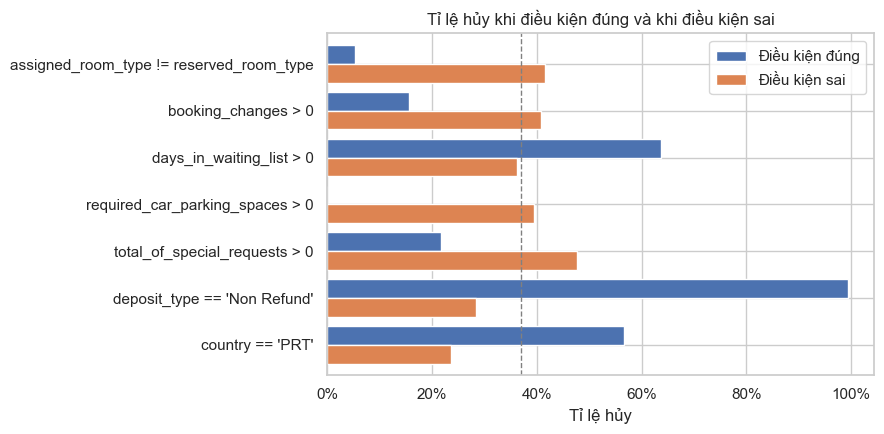

In [31]:
suspects = {
    "assigned_room_type != reserved_room_type": df["assigned_room_type"] != df["reserved_room_type"],
    "booking_changes > 0": df["booking_changes"] > 0,
    "days_in_waiting_list > 0": df["days_in_waiting_list"] > 0,
    "required_car_parking_spaces > 0": df["required_car_parking_spaces"] > 0,
    "total_of_special_requests > 0": df["total_of_special_requests"] > 0,
    "deposit_type == 'Non Refund'": df["deposit_type"] == "Non Refund",
    "country == 'PRT'": df["country"] == "PRT",
}
evidence = pd.DataFrame({
    "n_bookings": {name: int(mask.sum()) for name, mask in suspects.items()},
    "cancel_rate_if_true": {name: df.loc[mask, TARGET].mean() for name, mask in suspects.items()},
    "cancel_rate_if_false": {name: df.loc[~mask, TARGET].mean() for name, mask in suspects.items()},
})
display(evidence)

fig, ax = plt.subplots(figsize=(9, 4.5))
evidence[["cancel_rate_if_true", "cancel_rate_if_false"]].rename(columns={
    "cancel_rate_if_true": "Điều kiện đúng",
    "cancel_rate_if_false": "Điều kiện sai",
}).plot.barh(ax=ax, width=0.8)
ax.invert_yaxis()
ax.axvline(pos_rate, color="grey", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Tỉ lệ hủy")
ax.set_title("Tỉ lệ hủy khi điều kiện đúng và khi điều kiện sai")
fig.tight_layout()
save_figure(fig, "leakage_evidence")
plt.show()

`deposit_type = Non Refund` có tỉ lệ hủy rất cao, ngược với trực giác: khách đã trả toàn bộ tiền phòng lại hủy nhiều nhất. Phần dưới xem nhóm này đến từ đâu.

In [32]:
non_refund = df[df["deposit_type"] == "Non Refund"]
display(cancel_rate_table(non_refund, "market_segment"))
display(cancel_rate_table(non_refund, "hotel"))
print(f"Non Refund rows that have an identical copy: {non_refund.duplicated(keep=False).mean():.1%}")

,n_bookings,share,cancel_rate
market_segment,,,
Groups,9172,0.629,0.993
Offline TA/TO,5006,0.343,0.999
Corporate,334,0.023,0.934
Online TA,56,0.004,0.946
Direct,19,0.001,0.842


,n_bookings,share,cancel_rate
hotel,,,
City Hotel,12868,0.882,0.998
Resort Hotel,1719,0.118,0.960


Non Refund rows that have an identical copy: 98.1%


Kiểm tra thêm cho các cột REVIEW dự định giữ: có mức nào (hơn 12 booking) có tỉ lệ hủy ≤ 5% hoặc ≥ 95% không?

In [33]:
kept_review_cols = ["adults", "children", "babies", "stays_in_weekend_nights", "stays_in_week_nights",
                    "meal", "reserved_room_type", "market_segment", "distribution_channel",
                    "customer_type", "agent", "company"]
extreme_levels = {}
for col in kept_review_cols:
    stats = df.groupby(col)[TARGET].agg(n_bookings="size", cancel_rate="mean")
    extreme = stats[(stats["n_bookings"] > 12)
                    & ((stats["cancel_rate"] <= 0.05) | (stats["cancel_rate"] >= 0.95))]
    extreme_levels[col] = extreme
    print(f"{col:<26} extreme levels: {len(extreme):>3}  bookings: {int(extreme['n_bookings'].sum()):>5,}")

for col in ["agent", "company"]:
    display(extreme_levels[col].sort_values("n_bookings", ascending=False).head(5))

adults                     extreme levels:   0  bookings:     0
children                   extreme levels:   0  bookings:     0
babies                     extreme levels:   0  bookings:     0
stays_in_weekend_nights    extreme levels:   0  bookings:     0
stays_in_week_nights       extreme levels:   0  bookings:     0
meal                       extreme levels:   0  bookings:     0
reserved_room_type         extreme levels:   0  bookings:     0
market_segment             extreme levels:   0  bookings:     0
distribution_channel       extreme levels:   0  bookings:     0
customer_type              extreme levels:   0  bookings:     0
agent                      extreme levels:  43  bookings: 2,163
company                    extreme levels:  30  bookings:   834


,n_bookings,cancel_rate
agent,,
236.000,247,1.000
152.000,183,0.033
326.000,165,0.976
31.000,162,0.951
220.000,104,0.010


,n_bookings,cancel_rate
company,,
154.000,133,0.038
242.000,62,0.032
348.000,59,1.000
342.000,48,0.042
202.000,38,1.000


**Tổng hợp cho M1** (cột "Theo bài báo" lấy từ Table 1 và Mục 2 của bài báo gốc; cột "Đề xuất cho M1" là đề xuất cho **bộ cột sạch**, còn bộ cột thông thường vẫn chỉ bỏ `reservation_status` theo thiết kế TN1):

| Cột | Theo bài báo | T04 hiện tại | Đề xuất cho M1 |
|---|---|---|---|
| `reservation_status` | Trạng thái cuối của booking | DROP | **Bỏ (cả hai bộ).** Khớp 100% với target (Canceled/No-Show ↔ 1, Check-Out ↔ 0): đây chính là nhãn. |
| `reservation_status_date` | Ngày đặt trạng thái cuối; dùng để biết booking bị hủy khi nào | DROP | **Bỏ.** 95,3% booking hủy có ngày này trước ngày đến, còn booking Check-Out luôn có ngày ≥ ngày đến, nên gần như suy ra được nhãn. |
| `assigned_room_type` | Phòng được giao, có thể khác phòng đặt vì vận hành hoặc yêu cầu khách | DROP | **Bỏ.** Khi phòng được giao khác phòng đặt, tỉ lệ hủy chỉ 5,4% (so với 41,6%): phòng thường được giao lúc check-in, mà booking hủy thì không check-in. |
| `booking_changes` | Đếm số lần sửa đến lúc check-in hoặc hủy | DROP | **Bỏ.** Có sửa thì hủy 15,7% so với 40,9%: số lần sửa đếm đến lúc check-in hoặc hủy, nên booking hủy sớm có ít thời gian để bị sửa. |
| `days_in_waiting_list` | Ngày xác nhận − ngày nhập vào hệ thống | DROP | **Bỏ.** Chỉ biết sau khi booking được xác nhận, không phải lúc khách gửi yêu cầu. Ảnh hưởng nhỏ: chỉ 3.698 booking (3,1%) có giá trị > 0. |
| `deposit_type` | Tính từ các khoản thanh toán trước ngày đến hoặc ngày hủy | REVIEW | **Bỏ.** Giá trị được tính từ các khoản thanh toán đến ngày đến/ngày hủy, không phải điều khoản lúc đặt. Non Refund hủy 99,4% (ngược trực giác); 88,2% ở City, 97% thuộc Groups/Offline TA/TO, 98,1% có dòng trùng, giống các khối phòng đoàn bị hủy hàng loạt. Đây là cột gây tranh luận nhất, nhóm cần thống nhất. |
| `country` | Khách sạn thường chỉ biết đúng quốc tịch khi check-in | REVIEW | **Bỏ.** Booking hủy thì không check-in, nên giá trị ở hai lớp được ghi theo hai cơ chế khác nhau. PRT hủy 56,6% so với 23,6%; không tách được "khách nội địa hủy nhiều" với "quốc tịch chưa được cập nhật". |
| `required_car_parking_spaces` | Không nói riêng; quy tắc chung là lấy trạng thái ngày trước ngày đến | REVIEW | **Bỏ.** 7.416 booking có yêu cầu đỗ xe và không booking nào bị hủy (0,0%). Một yêu cầu nhập lúc đặt khó cho kết quả hoàn hảo như vậy; nhiều khả năng chỗ đỗ được ghi nhận khi khách đến. |
| `total_of_special_requests` | Không nói riêng; quy tắc chung như trên | REVIEW | **Giữ, ghi vào hạn chế.** Có yêu cầu thì hủy 21,7% so với 47,7%: giảm mạnh nhưng không về 0, và nhiều yêu cầu được nhập ngay trên form đặt phòng. Rủi ro: yêu cầu thêm sau khi đặt cũng được cộng vào. Nếu kịp, chạy thêm bộ sạch bỏ cột này để xem độ nhạy. |
| `adults`, `children`, `babies`, `stays_*`, `meal`, `reserved_room_type` | Khách thường đổi các thuộc tính này, kể cả lúc check-in | REVIEW | **Giữ, ghi vào hạn chế.** Đây là nội dung chính của yêu cầu đặt phòng. Có thể bị sửa sau, nhưng không có dấu hiệu rò rỉ: số đêm phân bố như nhau ở hai lớp, và các mức có tỉ lệ hủy gần 0%/100% đều chỉ có n ≤ 12. |
| `market_segment`, `distribution_channel`, `customer_type`, `agent`, `company`, `adr` | Không nói riêng; quy tắc chung như trên | REVIEW | **Giữ.** Về nghiệp vụ, kênh, đại lý, công ty, loại khách và giá thường được xác định khi tạo booking. `market_segment`, `distribution_channel`, `customer_type` không có mức nào hủy gần 0%/100% với n > 12 (cao nhất là Groups 61%). Riêng `agent` có 43 mã và `company` có 30 mã hủy ≤ 5% hoặc ≥ 95% (lớn nhất: agent 236 hủy 100%, n = 247; xem ô code ở trên), nhưng đó là đặc điểm của từng đại lý hoặc khối đoàn, không có cơ chế ghi nhận sau lúc đặt. Rủi ro là mô hình học thuộc mã đại lý khi chia ngẫu nhiên; gom mức hiếm (`min_frequency`) giảm bớt rủi ro này. `adr` tương quan rất yếu với target (ρ = 0,05). |

**Nhận xét chung về leakage:**

- **Có hai mức độ leakage:**
  1. *Rò rỉ nhãn trực tiếp:* `reservation_status` chính là nhãn, còn `reservation_status_date` gần như suy ra được nhãn. Hai cột này không còn gì phải bàn.
  2. *Rò rỉ do thời điểm ghi nhận:* giá trị trong dataset là trạng thái ngày trước ngày đến, nên các cột được tích lũy theo thời gian hoặc cập nhật khi check-in sẽ mang thông tin "khách có đến hay không": `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`, `country`, `deposit_type`. Điểm chung của các cột này là tỉ lệ hủy lệch cực mạnh về một phía (0,0%; 5,4%; 99,4%) trên hàng nghìn booking, *và* có cơ chế giải thích từ bài báo.
- **Thống kê chỉ là dấu hiệu.** `lead_time` và `total_of_special_requests` cũng tương quan mạnh với target nhưng có lý do nghiệp vụ hợp lệ. Quy tắc nhóm có thể dùng: chỉ bỏ cột khi có **cả** (a) cơ chế ghi nhận sau lúc đặt **và** (b) dấu hiệu thống kê bất thường. Nếu chỉ có (a) mà không có (b), giữ lại và ghi vào hạn chế. Quy tắc này tránh bỏ quá nhiều cột hợp lệ, vốn sẽ làm TN1 khó diễn giải.
- **Bộ cột sạch đề xuất (23 cột):** 9 cột KEEP của T04 cùng 14 cột REVIEW được giữ ở bảng trên. So với T04, bộ này bỏ thêm 3 cột: `deposit_type`, `country`, `required_car_parking_spaces`. (`arrival_date_year` vẫn nằm trong danh sách theo T04, nhưng nên cân nhắc bỏ khi chia theo thời gian, xem Mục 4.)
- **Bộ cột thông thường (30 cột):** chỉ bỏ target và `reservation_status`. Lưu ý cho TV1: `reservation_status_date` là chuỗi ngày với 926 giá trị khác nhau. Mức độ "lạc quan" của bộ này phụ thuộc vào cách mã hóa cột đó: one-hot nguyên dạng thì mô hình khó dùng, còn đổi thành số ngày so với ngày đến thì gần như lộ nhãn. Cần ghi rõ cách mã hóa trong báo cáo.
- **Leakage và dòng trùng cộng dồn:** 98,1% dòng Non Refund có bản sao. Với chia ngẫu nhiên, hai nguồn lạc quan (cột rò rỉ và bản sao nằm ở cả train lẫn test) cộng dồn vào ô "thông thường + ngẫu nhiên". Đây chính là điều TN1 muốn đo.
- **Hạn chế cho mục 5.3:** ngay cả bộ sạch vẫn là trạng thái ngày trước ngày đến (`adults`, `stays_*`, `meal`, `adr`, ... có thể đã bị sửa), nên kết quả của bộ sạch có thể vẫn hơi lạc quan so với dự đoán thật tại lúc đặt.

```python
CLEAN_FEATURES = [  # proposal for M1
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month",
    "arrival_date_week_number", "arrival_date_day_of_month",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "meal", "reserved_room_type", "market_segment", "distribution_channel",
    "customer_type", "agent", "company", "adr", "total_of_special_requests",
]
```

## 10. Outlier

**Mục đích:**
- Quy tắc IQR gắn cờ các giá trị nằm ngoài [Q1 − 1,5·IQR, Q3 + 1,5·IQR].
- Đây chỉ là cờ báo: với biến lệch, nhiều giá trị thật cũng bị gắn cờ.
- Cần xem từng trường hợp:
  - Nếu là lỗi nhập liệu: loại hoặc sửa.
  - Nếu là giá trị thật nhưng hiếm: giữ lại, và cân nhắc biến đổi (log, cắt ngưỡng) trong Pipeline cho Logistic Regression.

,q1,q3,lower,upper,n_outside,min,max
lead_time,18.000,160.000,-195.000,373.000,3005,0.000,737.000
adr,69.290,126.000,-15.775,211.065,3793,-6.380,5400.000
stays_in_weekend_nights,0.000,2.000,-3.000,5.000,265,0.000,19.000
stays_in_week_nights,1.000,3.000,-2.000,6.000,3354,0.000,50.000
adults,2.000,2.000,2.000,2.000,29710,0.000,55.000


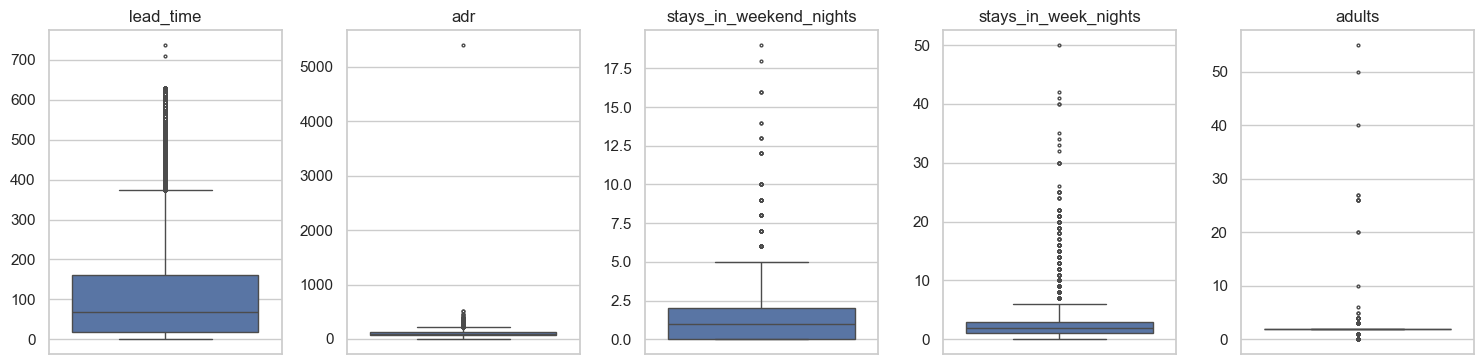

In [34]:
outlier_cols = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights", "adults"]
rows = {}
for col in outlier_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows[col] = {
        "q1": q1, "q3": q3, "lower": low, "upper": high,
        "n_outside": int(((df[col] < low) | (df[col] > high)).sum()),
        "min": df[col].min(), "max": df[col].max(),
    }
display(pd.DataFrame(rows).T.astype({"n_outside": int}))

fig, axes = plt.subplots(1, len(outlier_cols), figsize=(15, 3.8))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0", flierprops={"markersize": 2})
    ax.set_title(col)
    ax.set_ylabel("")
fig.tight_layout()
save_figure(fig, "outliers_boxplot")
plt.show()

In [35]:
show_cols = ["hotel", "lead_time", "adults", "children", "babies", "stays_in_weekend_nights",
             "stays_in_week_nights", "adr", "market_segment", TARGET]
display(df.nlargest(5, "adr")[show_cols])
display(df[df["adr"] < 0][show_cols])
display(df.nlargest(5, "adults")[show_cols])
display(df[(df["children"] >= 9) | (df["babies"] >= 9)][show_cols])

,hotel,lead_time,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,market_segment,is_canceled
48515,City Hotel,35,2,0.000,0,0,1,5400.000,Offline TA/TO,1
111403,City Hotel,0,1,0.000,0,0,1,510.000,Offline TA/TO,0
15083,Resort Hotel,1,2,0.000,0,0,1,508.000,Corporate,0
103912,City Hotel,81,2,2.000,0,1,1,451.500,Direct,0
13142,Resort Hotel,378,2,0.000,0,4,10,450.000,Online TA,1


,hotel,lead_time,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,market_segment,is_canceled
14969,Resort Hotel,195,2,0.000,0,4,6,-6.380,Groups,0


,hotel,lead_time,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,market_segment,is_canceled
2173,Resort Hotel,338,55,0.000,0,2,0,0.000,Direct,1
1643,Resort Hotel,336,50,0.000,0,1,2,0.000,Direct,1
1539,Resort Hotel,304,40,0.000,0,0,3,0.000,Direct,1
1917,Resort Hotel,349,27,0.000,0,1,3,0.000,Direct,1
1962,Resort Hotel,352,27,0.000,0,1,3,0.000,Direct,1


,hotel,lead_time,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,market_segment,is_canceled
328,Resort Hotel,55,2,10.000,0,4,10,133.160,Offline TA/TO,1
46619,City Hotel,37,2,0.000,10,0,2,84.450,Online TA,0
78656,City Hotel,11,1,0.000,9,2,1,95.000,Corporate,0


**Nhận xét:**

- **IQR gắn cờ nhiều, nhưng đa số là giá trị thật:**
  - `lead_time`: 3.005 dòng trên 373 ngày (tối đa 737). Đặt trước 1–2 năm là có thật (đoàn, hãng lữ hành), nên giữ.
  - `adr`: 3.793 dòng nằm ngoài [−15,8; 211,1]. Phần lớn là giá mùa cao điểm (phân bố `adr` của Resort có đuôi dài, Mục 5), nên giữ. Chỉ có 2 giá trị lỗi: −6,38 và 5.400.
  - `stays_in_week_nights` tối đa 50 đêm, `stays_in_weekend_nights` tối đa 19: ở dài ngày hiếm nhưng có thể có, nên giữ.
  - `adults`: Q1 = Q3 = 2 nên IQR = 0, và khoảng "bình thường" co lại đúng một giá trị là 2. Vì vậy mọi booking có 1, 3 hay 4 người lớn (29.710 dòng, ≈ 25% dữ liệu) đều bị gắn cờ. **Quy tắc IQR không phù hợp với biến đếm rời rạc có một giá trị chiếm đa số.**
- **Lỗi hoặc nghi lỗi:**
  - `adr` = −6,38 và `adr` = 5.400: lỗi (Mục 2.3).
  - 9–10 trẻ em hoặc trẻ sơ sinh đi cùng 1–2 người lớn (3 dòng): gần như chắc chắn là lỗi nhập.
  - `adults` từ 27 đến 55 (5 dòng lớn nhất): cả 5 đều là Resort, Direct, `adr` = 0, `lead_time` > 300 và đều bị hủy. Trông giống bản ghi giữ chỗ cho cả đoàn hơn là một phòng thật. Hiếm và nghi vấn, nhưng có thể giữ: mô hình cây không bị ảnh hưởng, còn với Logistic Regression thì cắt ngưỡng.
- **Đề xuất xử lý, chia thành hai bước khác nhau:**
  1. *Trước khi chia:* bỏ các dòng lỗi theo quy tắc nghiệp vụ cố định (`adr` < 0, `adr` > 1.000, không có khách, ≥ 9 trẻ em hoặc trẻ sơ sinh), tổng cộng 185 dòng. Quy tắc không học từ dữ liệu nên làm trước khi chia không gây leakage. Ghi số dòng bị bỏ vào báo cáo.
  2. *Trong Pipeline (fit trên train):* với Logistic Regression, dùng `log1p` cho `lead_time` và `adr`, cắt ngưỡng các biến đếm đuôi dài (`adults`, `stays_*`) theo ngưỡng nghiệp vụ cố định hoặc theo phân vị tính trên train, rồi chuẩn hóa. RF/GBM giữ nguyên.
- **Không lọc outlier theo IQR**, vì làm vậy sẽ xóa khoảng 1/4 booking thật (do `adults`) và khiến tập test không còn giống dữ liệu thực tế.

## 11. Ý tưởng đặc trưng cho T08

Mục này chỉ ghi ý tưởng, chưa viết code. Code sẽ nằm trong `src/features.py::add_features` sau M1.

| Đặc trưng | Cách tính | Cột nguồn (trạng thái T04) |
|---|---|---|
| `total_nights` | `stays_in_weekend_nights` + `stays_in_week_nights` | REVIEW |
| `total_guests`, `has_children` | `adults` + `children` + `babies`; có trẻ em hay không | REVIEW |
| `arrival_weekday` | Thứ trong tuần của ngày đến | KEEP |
| `booking_month`, `booking_weekday` | Từ ngày đặt = ngày đến − `lead_time` | KEEP |
| `prev_cancel_ratio` | `previous_cancellations` / (`previous_cancellations` + `previous_bookings_not_canceled`), bằng 0 nếu chưa từng đặt | KEEP |
| `has_agent`, `has_company` | `agent`/`company` khác NULL | REVIEW |
| `country_group` | PRT / nước khác / thiếu, hoặc top-N + "Other" | REVIEW |
| `meal` gộp | Gộp `Undefined` vào `SC` (cùng nghĩa theo bài báo) | REVIEW |

**Lý do chọn đặc trưng:**

| Đặc trưng | Quyết định | Bằng chứng | Dùng cho |
|---|---|---|---|
| `has_agent`, `has_company` | **Làm (ưu tiên cao)** | Mục 2.1: không qua đại lý hủy 24,7% so với 39,0%; có công ty hủy 17,5% so với 38,2%. `has_company` thay cho 352 mã công ty (94,3% thiếu). | Cả hai bộ (nếu M1 giữ `agent`, `company`) |
| `prev_cancel_ratio` + `has_history` | **Làm (ưu tiên cao)** | Mục 6: `previous_bookings_not_canceled` ≥ 1 chỉ hủy 5–6%, còn `previous_cancellations` ≥ 1 hủy nhiều. Tỉ lệ gộp hai chiều thông tin thành một số dễ hiểu, có ích cho Logistic Regression (mô hình này không tự tạo tương tác). Cần thêm `has_history` vì giá trị 0 đang gộp chung "chưa từng đặt" với "đã đặt nhưng chưa hủy lần nào". | Cả hai bộ (cột nguồn KEEP) |
| `meal` gộp `Undefined` → `SC` | **Làm** (bước làm sạch hơn là đặc trưng mới) | Mục 2.3: `Undefined` chỉ có ở Resort, `SC` gần như chỉ có ở City; bài báo nói hai mức cùng nghĩa. Cần cho TN2. | Cả hai bộ |
| `has_children` | **Tùy chọn (ưu tiên thấp)** | Mục 6: bằng chứng yếu và không nhất quán (`children` = 1 hủy 32%, = 2 hủy 42%; `babies` ≥ 1 hủy 13–18%). Chỉ đáng làm nếu Logistic Regression cần một cờ gọn thay cho hai cột đếm thưa. | Cả hai bộ |
| `total_guests` | **Bỏ** | Không có bằng chứng riêng; 75% booking có đúng 2 người lớn. Phép cộng chỉ cần cho quy tắc lọc booking không có khách (Mục 2.3), không cần thành đặc trưng. | — |
| `total_nights` | **Bỏ** | Mục 6: tổng số đêm phân bố gần như giống hệt nhau ở hai lớp (trung vị 3, IQR 2–4). | — |
| `arrival_weekday` | **Bỏ ở vòng này** | EDA chưa xem thứ trong tuần nên chưa có bằng chứng; có thể kiểm tra lại trên train nếu kịp. | — |
| `booking_month`, `booking_weekday` | **Bỏ** | Ngày đặt = ngày đến − `lead_time`, nên thông tin đã nằm trong `arrival_date_*` và `lead_time`. Biến động theo quý đặt ở Mục 4 chủ yếu do cách cắt dữ liệu và các khối booking đoàn. | — |
| `country_group` | **Chỉ cho bộ thông thường** | Mục 7: PRT hủy 57% so với 17–37% ở các nước khác; PRT / nước khác / thiếu giữ phần lớn tín hiệu với 3 mức. Nếu M1 bỏ `country` khỏi bộ sạch (đề xuất ở Mục 9.3) thì đặc trưng này cũng không được dùng cho bộ sạch. | Bộ thông thường |

**Nguyên tắc cài đặt `add_features`:**

- Chỉ làm phép biến đổi trên từng dòng, không dùng thống kê của dữ liệu (top-N, trung bình, ...), nên gọi trước khi chia vẫn an toàn. Phần nào cần "học" từ dữ liệu (gom mức hiếm, log + chuẩn hóa) thì để trong Pipeline.
- Không tạo đặc trưng từ cột bị loại khỏi bộ sạch (vd. `room_changed` = `assigned_room_type` ≠ `reserved_room_type`); nếu có thì chỉ dùng cho bộ thông thường.

## 12. Tóm tắt thách thức dữ liệu

Cột "Bằng chứng" được tính trực tiếp từ dữ liệu, nên số liệu luôn khớp với notebook. Phần này dùng cho mục 2.2 của báo cáo.

In [36]:
n_rows = len(df)
n_dup = df.duplicated().sum()
missing_share = df[["company", "agent"]].isna().mean()
parking_rate = df.loc[df["required_car_parking_spaces"] > 0, TARGET].mean()
non_refund_rate = df.loc[df["deposit_type"] == "Non Refund", TARGET].mean()
zero_guests = int((df[["adults", "children", "babies"]].fillna(0).sum(axis=1) == 0).sum())
zero_nights = int((df["stays_in_weekend_nights"] + df["stays_in_week_nights"] == 0).sum())
hotel_rate = df.groupby("hotel")[TARGET].mean()

challenges = pd.DataFrame(
    [
        ("Mất cân bằng lớp",
         f"Tỉ lệ hủy {pos_rate:.1%}; luôn đoán 'không hủy' đạt accuracy {1 - pos_rate:.1%}"),
        ("Dòng trùng hoàn toàn",
         f"{n_dup:,} dòng ({n_dup / n_rows:.1%}); không có mã booking để phân biệt"),
        ("Leakage và thời điểm ghi nhận",
         f"reservation_status khớp hoàn toàn với target; parking > 0 có tỉ lệ hủy {parking_rate:.1%}; "
         f"Non Refund có tỉ lệ hủy {non_refund_rate:.1%}; giá trị là trạng thái ngày trước ngày đến"),
        ("Giá trị thiếu mang nghĩa 'không áp dụng'",
         f"company thiếu {missing_share['company']:.1%}, agent thiếu {missing_share['agent']:.1%}, "
         f"country thiếu {df['country'].isna().sum():,} dòng"),
        ("Biến phân loại nhiều mức",
         f"country {df['country'].nunique()} mức, agent {df['agent'].nunique()}, company {df['company'].nunique()}"),
        ("Phân phối lệch và outlier",
         f"lead_time lệch {df['lead_time'].skew():.2f}, tối đa {df['lead_time'].max()} ngày; "
         f"adr từ {df['adr'].min():.2f} đến {df['adr'].max():,.0f}"),
        ("Giá trị không hợp lệ",
         f"{zero_guests} booking không có khách; {zero_nights} booking 0 đêm; "
         f"meal 'Undefined' {int((df['meal'] == 'Undefined').sum()):,} dòng"),
        ("Thay đổi theo thời gian",
         f"Tỉ lệ hủy theo tháng và khách sạn dao động {monthly['cancel_rate'].min():.1%}–"
         f"{monthly['cancel_rate'].max():.1%}; năm 2017 chỉ có đến tháng 8"),
        ("Khác biệt giữa hai khách sạn",
         f"City hủy {hotel_rate['City Hotel']:.1%}, Resort hủy {hotel_rate['Resort Hotel']:.1%}"),
    ],
    columns=["Thách thức", "Bằng chứng"],
    index=range(1, 10),
)
with pd.option_context("display.max_colwidth", None):
    display(challenges)

,Thách thức,Bằng chứng
1,Mất cân bằng lớp,Tỉ lệ hủy 37.0%; luôn đoán 'không hủy' đạt accuracy 63.0%
2,Dòng trùng hoàn toàn,"31,994 dòng (26.8%); không có mã booking để phân biệt"
3,Leakage và thời điểm ghi nhận,reservation_status khớp hoàn toàn với target; parking > 0 có tỉ lệ hủy 0.0%; Non Refund có tỉ lệ hủy 99.4%; giá trị là trạng thái ngày trước ngày đến
4,Giá trị thiếu mang nghĩa 'không áp dụng',"company thiếu 94.3%, agent thiếu 13.7%, country thiếu 488 dòng"
5,Biến phân loại nhiều mức,"country 177 mức, agent 333, company 352"
6,Phân phối lệch và outlier,"lead_time lệch 1.35, tối đa 737 ngày; adr từ -6.38 đến 5,400"
7,Giá trị không hợp lệ,"180 booking không có khách; 715 booking 0 đêm; meal 'Undefined' 1,169 dòng"
8,Thay đổi theo thời gian,Tỉ lệ hủy theo tháng và khách sạn dao động 13.5%–67.2%; năm 2017 chỉ có đến tháng 8
9,Khác biệt giữa hai khách sạn,"City hủy 41.7%, Resort hủy 27.8%"


**Hướng xử lý dự kiến** (đề xuất của TV2, cần chốt ở M1):

| # | Thách thức | Hướng xử lý dự kiến |
|---|---|---|
| 1 | Mất cân bằng lớp | Mất cân bằng nhẹ (1,7 : 1), không resample. Metric chính là PR-AUC (ghi kèm mốc = tỉ lệ hủy của tập test) và F1 lớp hủy. Stratify khi chia ngẫu nhiên và khi CV; thử `class_weight="balanced"` như một siêu tham số; ngưỡng chọn trên validation (TN3). |
| 2 | Dòng trùng | Giữ lại, vì nhiều khả năng là booking thật của đoàn. Chia theo thời gian/khách sạn tự giữ các bản sao cùng một phía. Với chia ngẫu nhiên (TN1), báo thêm tỉ lệ dòng test có bản sao trong train để giải thích phần chênh lệch. |
| 3 | Leakage | Bộ sạch 23 cột (so với T04, bỏ thêm `deposit_type`, `country`, `required_car_parking_spaces`); bộ thông thường chỉ bỏ `reservation_status`. Thêm `assert` trong code để chặn cột cấm lọt vào X. |
| 4 | Giá trị thiếu | `agent`/`company`: NaN thành nhóm "None", kèm cờ `has_agent`/`has_company`. `children`: điền 0. `country` (nếu giữ): "Unknown". Imputer đặt trong Pipeline. |
| 5 | Nhiều mức | `OneHotEncoder(min_frequency=..., handle_unknown="infrequent_if_exist")` fit trên train; `company` chỉ dùng `has_company`; không target-encode ngoài Pipeline. |
| 6 | Lệch và outlier | Giữ giá trị thật, không lọc theo IQR. LR: `log1p` cho `lead_time`, `adr`; cắt ngưỡng biến đếm đuôi dài; `StandardScaler` trong Pipeline. RF/GBM: giữ nguyên. |
| 7 | Không hợp lệ | Bỏ 185 dòng lỗi theo quy tắc cố định trước khi chia (`adr` < 0, `adr` > 1.000, 0 khách, ≥ 9 trẻ em/trẻ sơ sinh). Gộp `meal` `Undefined` → `SC`. Giữ booking 0 đêm và `adr` = 0 (Complementary). |
| 8 | Thay đổi theo thời gian | Chia theo ngày đến: train 07/2015–12/2016, validation 01–04/2017, test 05–08/2017 (đề xuất cho T05). CV bằng `TimeSeriesSplit` sau khi sort theo ngày đến. Cân nhắc không dùng `arrival_date_year` làm đặc trưng. |
| 9 | Khác biệt hai khách sạn | Giữ `hotel` làm đặc trưng trong các thí nghiệm chính. TN2: dự kiến giảm ở cả hai chiều, City → Resort tốt hơn chiều ngược lại; so PR-AUC theo mức vượt mốc của khách sạn test; bỏ cột `hotel`. |

### Câu hỏi mang đến buổi họp M1
1. Bộ cột sạch gồm những cột nào (dựa trên Mục 9)?
2. Giữ hay bỏ các dòng trùng (Mục 2.2)?
3. Chia theo thời gian dựa trên ngày đến hay ngày đặt, và mốc cắt ở đâu (Mục 4, phối hợp với TV3)?
4. Metric chính PR-AUC và F1 lớp hủy có hợp lý với tỉ lệ hủy ở Mục 3 không?